# 02 - Sentinel-2 L2A Acquisition & Bellandur Verification

This notebook verifies end-to-end retrieval, windowed reading, polygon boundary clipping, radiometric/nodata preprocessing, spectral index calculation, and visual water-mask diagnostics for **Bellandur Lake** using Sentinel-2 Level-2A imagery from the **Microsoft Planetary Computer STAC API**.

## 1. Environment Setup and Imports

Import the STAC client, Planetary Computer signing helper, Rasterio windowed reading and reprojection utilities, and core numerical/plotting libraries.

In [1]:
import pystac_client
import planetary_computer
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.enums import Resampling

## 2. Study Locations (WGS84 / `EPSG:4326`)

Each water body's Area of Interest (AOI) is defined in the **WGS84 (`EPSG:4326`)** geographic coordinate reference system using standard STAC/GeoJSON bounding box order:

`[min_lon, min_lat, max_lon, max_lat]` (i.e., `[West, South, East, North]`).

All four project study locations from `SPEC.md` are registered below for STAC scene searches, while satellite scene retrieval and verification in this notebook are executed **only for Bellandur Lake**.

In [2]:
WATER_BODIES = {
    "bellandur": [77.645, 12.920, 77.685, 12.946],
    "hussain_sagar": [78.455, 17.408, 78.492, 17.442],
    "yamuna_okhla": [77.292, 28.545, 77.322, 28.575],
    "sukhna": [76.803, 30.733, 76.835, 30.752],
}

print("Registered study locations:", list(WATER_BODIES.keys()))
print("Active verification target: bellandur ->", WATER_BODIES["bellandur"])

Registered study locations: ['bellandur', 'hussain_sagar', 'yamuna_okhla', 'sukhna']
Active verification target: bellandur -> [77.645, 12.92, 77.685, 12.946]


## 3. Connect to Microsoft Planetary Computer STAC API

- **What STAC is:** The **SpatioTemporal Asset Catalog (STAC)** is an open specification that standardizes geospatial metadata so satellite scenes (Items), spectral bands (Assets), and datasets (Collections) can be queried uniformly by space, time, and properties such as cloud cover.
- **Why Microsoft Planetary Computer:** It hosts a free, analysis-ready archive of Cloud-Optimized GeoTIFFs (COGs) with fast STAC search and signed URL access via `planetary-computer`, eliminating manual bulk tile downloads from Copernicus.
- **How it provides Sentinel-2 access:** Querying the `sentinel-2-l2a` collection returns STAC items containing georeferenced COG URLs (`B02`–`B08`, `B8A`, `SCL`, etc.) and scene metadata (`eo:cloud_cover`, `s2:processing_baseline`), allowing Rasterio to stream only the small geographical window covering Bellandur Lake.

In [3]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

if catalog is None or not getattr(catalog, "title", None):
    raise ConnectionError("Failed to connect to Microsoft Planetary Computer STAC API.")

print("Catalog title:", catalog.title)

Catalog title: Microsoft Planetary Computer STAC API


## 4. Search for Bellandur Sentinel-2 L2A Scenes

Query the `sentinel-2-l2a` collection over the Bellandur bounding box for scenes with tile-wide cloud cover below 20%.

In [4]:
bbox = WATER_BODIES["bellandur"]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2025-05-01/2026-11-24",
    query={"eo:cloud_cover": {"lt": 20}},
    max_items=50,
)

items = list(search.items())

print("Scenes found:", len(items))

if len(items) == 0:
    raise RuntimeError(
        "No Sentinel-2 L2A scenes were returned for Bellandur. "
        "Verify the collection name ('sentinel-2-l2a'), bounding box "
        f"({bbox}), and date range ('2025-05-01/2026-11-24')."
    )

for item in items[:5]:
    print(
        item.id,
        item.datetime,
        item.properties.get("eo:cloud_cover"),
    )

Scenes found: 33
S2C_MSIL2A_20261123T051121_R019_T43PGQ_20261123T095510 2026-11-23 05:11:21.025000+00:00 0.000115
S2B_MSIL2A_20261118T051109_R019_T43PGQ_20261118T084845 2026-11-18 05:11:09.024000+00:00 5.93146
S2B_MSIL2A_20261029T050929_R019_T43PGQ_20261029T105708 2026-10-29 05:09:29.024000+00:00 0.018799
S2C_MSIL2A_20261014T050751_R019_T43PGQ_20261014T100514 2026-10-14 05:07:51.025000+00:00 8.237084
S2B_MSIL2A_20260512T050649_R019_T43PGQ_20260512T085408 2026-05-12 05:06:49.024000+00:00 12.85395


## 5. Select a Locally Clear Bellandur Scene and Inspect Assets

Tile-wide `eo:cloud_cover` can be misleading: a 100 km × 100 km Sentinel-2 tile may have low overall cloud cover while a localized cloud sits directly over Bellandur Lake (or vice versa, Bellandur may lie near a partial tile edge).

To ensure genuine local data quality, we read **only the Bellandur `SCL` window** for the top low-cloud candidate scenes and enforce both criteria:
- **Non-nodata coverage over Bellandur:** `> 95%`
- **Local cloud/shadow pixels (`SCL` in `{3, 8, 9, 10}`):** `< 10%`

We also verify availability of all nine required Sentinel-2 assets (`B02`, `B03`, `B04`, `B05`, `B06`, `B07`, `B08`, `B8A`, `SCL`).

In [5]:
REQUIRED_ASSETS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "SCL"]
SEARCH_INVALID_SCL = {0, 1, 3, 8, 9, 10}
CLOUD_SHADOW_CLASSES = {3, 8, 9, 10}

candidates = sorted(
    items,
    key=lambda it: (it.properties.get("eo:cloud_cover", 100.0), -it.datetime.timestamp()),
)[:10]

candidate_records = []
qualified_candidates = []

for cand in candidates:
    if "SCL" not in cand.assets:
        continue
    with rasterio.open(cand.assets["SCL"].href) as src:
        proj_bbox = transform_bounds("EPSG:4326", src.crs, *bbox)
        win = from_bounds(*proj_bbox, transform=src.transform)
        scl_win = src.read(1, window=win, boundless=True, fill_value=0)

    non_nodata_mask = scl_win != 0
    non_nodata_pct = float(np.mean(non_nodata_mask) * 100.0)
    valid_pct = float(np.mean(~np.isin(scl_win, list(SEARCH_INVALID_SCL))) * 100.0)
    if np.any(non_nodata_mask):
        cloud_shadow_pct = float(
            np.mean(np.isin(scl_win[non_nodata_mask], list(CLOUD_SHADOW_CLASSES))) * 100.0
        )
    else:
        cloud_shadow_pct = 100.0

    has_all_assets = all(band in cand.assets for band in REQUIRED_ASSETS)
    passes = (non_nodata_pct > 95.0) and (cloud_shadow_pct < 10.0) and has_all_assets

    record = {
        "scene_id": cand.id,
        "datetime": cand.datetime.isoformat(),
        "tile_cloud_pct": cand.properties.get("eo:cloud_cover"),
        "non_nodata_pct": round(non_nodata_pct, 2),
        "local_valid_pct": round(valid_pct, 2),
        "local_cloud_shadow_pct": round(cloud_shadow_pct, 2),
        "has_all_assets": has_all_assets,
        "passes_criteria": passes,
    }
    candidate_records.append(record)
    if passes:
        qualified_candidates.append((cloud_shadow_pct, -non_nodata_pct, -cand.datetime.timestamp(), cand, record))

candidates_df = pd.DataFrame(candidate_records)
print(candidates_df.to_string(index=False))

if not qualified_candidates:
    raise RuntimeError(
        "No inspected Bellandur candidate satisfies >95% non-nodata coverage "
        "and <10% local cloud/shadow pixels with all 9 required assets."
    )

qualified_candidates.sort(key=lambda x: (x[0], x[1], x[2]))
_, _, _, selected_item, selected_metrics = qualified_candidates[0]

print("\nSelected scene ID:", selected_item.id)
asset_availability = {band: (band in selected_item.assets) for band in REQUIRED_ASSETS}
print("Required asset availability:", asset_availability)

                                              scene_id                         datetime  tile_cloud_pct  non_nodata_pct  local_valid_pct  local_cloud_shadow_pct  has_all_assets  passes_criteria
S2C_MSIL2A_20251208T051221_R019_T43PGQ_20251208T081319 2025-12-08T05:12:21.025000+00:00        0.000057           100.0            100.0                     0.0            True             True
S2C_MSIL2A_20261123T051121_R019_T43PGQ_20261123T095510 2026-11-23T05:11:21.025000+00:00        0.000115           100.0            100.0                     0.0            True             True
S2B_MSIL2A_20260201T050929_R019_T43PGQ_20260201T085208 2026-02-01T05:09:29.024000+00:00        0.000253           100.0            100.0                     0.0            True             True
S2C_MSIL2A_20260206T051011_R019_T43PGQ_20260206T101110 2026-02-06T05:10:11.025000+00:00        0.000289           100.0            100.0                     0.0            True             True
S2B_MSIL2A_20260122T051019_R01

## 6. Metadata Inspection and Remote-Sensing Explanation

### Why Sentinel-2 Level-2A?
Sentinel-2 **Level-2A (L2A)** provides atmospherically corrected **Bottom-of-Atmosphere (BOA) surface reflectance** rather than raw Top-of-Atmosphere radiance. Because water bodies are dark targets whose signal is easily dominated by atmospheric Rayleigh and aerosol scattering, L2A correction is essential for reliable spectral index calculation, cross-date comparison, and transfer to bio-optical water-quality models.

### Why are `B03`, `B08`, `B8A`, and `SCL` essential?
- **`B03` (Green, 560 nm, 10 m):** Water exhibits relatively higher reflectance in the green wavelength compared with NIR; `B03` forms the positive term in `NDWI` and `NDWI_B8A`, and anchors the 10 m reference grid.
- **`B08` (Broad NIR, 842 nm, 10 m) & `B8A` (Narrow NIR, 865 nm, 20 m):** Clear liquid water strongly absorbs NIR energy while terrestrial vegetation and land reflect NIR strongly, separating open water from vegetation and soil. `B8A` additionally avoids water-vapor absorption bands for cleaner aquatic spectral indices.
- **`SCL` (Scene Classification Layer, 20 m):** Provides per-pixel quality classification (water, vegetation, bare soil, dark/cast shadow, cloud shadow, medium/high cloud, cirrus, snow/ice, saturated, nodata) so contaminated pixels are excluded.

In [6]:
processing_baseline = selected_item.properties.get("s2:processing_baseline", "Unknown")

print("=== Selected Scene Metadata ===")
print(f"Scene ID:                         {selected_item.id}")
print(f"Acquisition Date (UTC):           {selected_item.datetime.isoformat()}")
print(f"Tile-Wide Cloud Cover (%):        {selected_item.properties.get('eo:cloud_cover')}")
print(f"Bellandur Non-Nodata Coverage:    {selected_metrics['non_nodata_pct']:.2f}%")
print(f"Bellandur Valid-Pixel Coverage:   {selected_metrics['local_valid_pct']:.2f}%")
print(f"Bellandur Local Cloud/Shadow (%): {selected_metrics['local_cloud_shadow_pct']:.2f}%")
print(f"Processing Baseline:              {processing_baseline}")

band_meta_rows = []
native_band_metadata = {}
for band in REQUIRED_ASSETS:
    available = band in selected_item.assets
    if available:
        with rasterio.open(selected_item.assets[band].href) as src:
            band_crs = str(src.crs)
            res_x, res_y = src.res
            native_res = f"{res_x:.0f}m x {res_y:.0f}m"
            native_band_metadata[band] = {
                "crs": band_crs,
                "native_resolution_m": (float(res_x), float(res_y)),
                "native_dtype": str(src.dtypes[0]),
            }
    else:
        band_crs = "N/A"
        native_res = "N/A"
    band_meta_rows.append({
        "Band": band,
        "Available": available,
        "CRS": band_crs,
        "Native_Resolution": native_res,
    })

band_meta_df = pd.DataFrame(band_meta_rows)
print("\n=== Required Band Assets Metadata ===")
print(band_meta_df.to_string(index=False))

=== Selected Scene Metadata ===
Scene ID:                         S2C_MSIL2A_20261123T051121_R019_T43PGQ_20261123T095510
Acquisition Date (UTC):           2026-11-23T05:11:21.025000+00:00
Tile-Wide Cloud Cover (%):        0.000115
Bellandur Non-Nodata Coverage:    100.00%
Bellandur Valid-Pixel Coverage:   100.00%
Bellandur Local Cloud/Shadow (%): 0.00%
Processing Baseline:              05.13



=== Required Band Assets Metadata ===
Band  Available        CRS Native_Resolution
 B02       True EPSG:32643         10m x 10m
 B03       True EPSG:32643         10m x 10m
 B04       True EPSG:32643         10m x 10m
 B05       True EPSG:32643         20m x 20m
 B06       True EPSG:32643         20m x 20m
 B07       True EPSG:32643         20m x 20m
 B08       True EPSG:32643         10m x 10m
 B8A       True EPSG:32643         20m x 20m
 SCL       True EPSG:32643         20m x 20m


## 7. Reusable Windowed Band-Reading & Validity-Aware Aligned Stack (Fix 4)

The helper functions below read all **9 required bands** (`B02`, `B03`, `B04`, `B05`, `B06`, `B07`, `B08`, `B8A`, `SCL`) aligned pixel-for-pixel onto the **10 m `B03` reference grid**:
1. **Exact 10 m reference grid:** Snap the Bellandur `from_bounds` window on `B03` to integer pixel boundaries so `target_shape`, `ref_transform`, `ref_crs`, and `exact_proj_bounds` are consistent across every band and polygon mask.
2. **Strict nodata handling before resampling:** Read each band at its native resolution (`10 m` or `20 m`) with `boundless=True, fill_value=0`. For reflectance bands, map raw `DN == 0` pixels to `np.nan` **before** applying baseline-aware scaling (`(raw - 1000.0) / 10000.0` for baseline `>= 04.00`, otherwise `raw / 10000.0`).
3. **Validity-aware resampling:** Resample 20 m spectral bands (`B05`, `B06`, `B07`, `B8A`) to the 10 m `B03` grid using `rasterio.warp.reproject(..., resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)` so nodata is never interpolated as valid reflectance. Resample `SCL` with `Resampling.nearest`, preserving integer classes.
4. **Negative reflectance preservation:** Preserve slightly negative surface reflectance values from atmospheric over-correction over dark water without silent clipping.

In [7]:
from rasterio.warp import reproject
from rasterio.windows import Window, bounds as window_bounds

SPECTRAL_BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A"]
ALL_STACK_BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "SCL"]


def get_reference_grid(item, wgs84_bbox, ref_band="B03"):
    """Determine the integer-aligned 10m reference grid shape, transform, CRS, and projected bounds from B03."""
    with rasterio.open(item.assets[ref_band].href) as src:
        proj_bbox = transform_bounds("EPSG:4326", src.crs, *wgs84_bbox)
        raw_win = from_bounds(*proj_bbox, transform=src.transform)
        col_start = int(np.floor(raw_win.col_off))
        row_start = int(np.floor(raw_win.row_off))
        col_stop = int(np.ceil(raw_win.col_off + raw_win.width))
        row_stop = int(np.ceil(raw_win.row_off + raw_win.height))
        aligned_win = Window(col_start, row_start, col_stop - col_start, row_stop - row_start)
        ref_transform = src.window_transform(aligned_win)
        exact_proj_bounds = window_bounds(aligned_win, src.transform)
        target_shape = (int(aligned_win.height), int(aligned_win.width))
        ref_crs = src.crs
    return {
        "target_shape": target_shape,
        "ref_transform": ref_transform,
        "ref_crs": ref_crs,
        "proj_bounds": exact_proj_bounds,
        "ref_window": aligned_win,
    }


def parse_processing_baseline(item):
    """Parse s2:processing_baseline as a float (e.g., '05.13' -> 5.13)."""
    baseline_str = item.properties.get("s2:processing_baseline")
    if baseline_str is None:
        raise ValueError("Missing 's2:processing_baseline' in STAC item properties.")
    return float(baseline_str)


def read_band_window(item, band_name, wgs84_bbox, grid_info=None, is_scl=False, return_raw=False):
    """Stream a windowed Sentinel-2 L2A band aligned to the 10m reference grid with validity-aware resampling."""
    if grid_info is None:
        grid_info = get_reference_grid(item, wgs84_bbox, ref_band="B03")

    target_shape = grid_info["target_shape"]
    dst_transform = grid_info["ref_transform"]
    dst_crs = grid_info["ref_crs"]

    with rasterio.open(item.assets[band_name].href) as src:
        if src.crs == dst_crs:
            proj_bbox = grid_info["proj_bounds"]
        else:
            proj_bbox = transform_bounds(dst_crs, src.crs, *grid_info["proj_bounds"])

        win = from_bounds(*proj_bbox, transform=src.transform)
        # Snap native window outward by 1 pixel to avoid edge truncation during bilinear resampling
        col_off = int(np.floor(win.col_off))
        row_off = int(np.floor(win.row_off))
        col_end = int(np.ceil(win.col_off + win.width))
        row_end = int(np.ceil(win.row_off + win.height))
        if (col_end - col_off, row_end - row_off) != (target_shape[1], target_shape[0]):
            col_off -= 1
            row_off -= 1
            col_end += 1
            row_end += 1
        native_win = Window(col_off, row_off, col_end - col_off, row_end - row_off)
        src_transform = src.window_transform(native_win)
        src_crs = src.crs
        raw_native = src.read(1, window=native_win, boundless=True, fill_value=0)

    # Check if already on the exact 10m reference grid
    exact_match = (
        raw_native.shape == target_shape
        and src_crs == dst_crs
        and src_transform.almost_equals(dst_transform, precision=1e-6)
    )

    if is_scl:
        scl_native = raw_native.astype(np.int16, copy=False)
        if exact_match:
            aligned_scl = scl_native
        else:
            aligned_scl = np.zeros(target_shape, dtype=np.int16)
            reproject(
                source=scl_native,
                destination=aligned_scl,
                src_transform=src_transform,
                src_crs=src_crs,
                dst_transform=dst_transform,
                dst_crs=dst_crs,
                resampling=Resampling.nearest,
            )
        return (aligned_scl, raw_native) if return_raw else aligned_scl

    # Reflectance band: map raw DN == 0 to np.nan BEFORE offset/scaling and resampling
    refl_native = raw_native.astype(np.float32)
    refl_native[raw_native == 0] = np.nan

    baseline_val = parse_processing_baseline(item)
    if baseline_val >= 4.0:
        refl_native = (refl_native - 1000.0) / 10000.0
    else:
        refl_native = refl_native / 10000.0

    if exact_match:
        aligned_refl = refl_native
        aligned_raw = raw_native
    else:
        aligned_refl = np.full(target_shape, np.nan, dtype=np.float32)
        reproject(
            source=refl_native,
            destination=aligned_refl,
            src_transform=src_transform,
            src_crs=src_crs,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            resampling=Resampling.bilinear,
            src_nodata=np.nan,
            dst_nodata=np.nan,
        )
        aligned_raw = np.zeros(target_shape, dtype=raw_native.dtype)
        reproject(
            source=raw_native,
            destination=aligned_raw,
            src_transform=src_transform,
            src_crs=src_crs,
            dst_transform=dst_transform,
            dst_crs=dst_crs,
            resampling=Resampling.nearest,
        )

    return (aligned_refl, aligned_raw) if return_raw else aligned_refl


def load_aligned_band_stack(item, wgs84_bbox, bands=ALL_STACK_BANDS, ref_band="B03"):
    """Load and align all 9 required Sentinel-2 L2A bands onto the 10m B03 reference grid."""
    grid_info = get_reference_grid(item, wgs84_bbox, ref_band=ref_band)
    band_arrays = {}
    raw_arrays = {}
    for band in bands:
        is_scl = (band == "SCL")
        arr, raw = read_band_window(
            item, band, wgs84_bbox, grid_info=grid_info, is_scl=is_scl, return_raw=True
        )
        band_arrays[band] = arr
        raw_arrays[band] = raw
    return band_arrays, raw_arrays, grid_info


def report_negative_reflectance(band_name, arr):
    """Report count, minimum, and maximum of negative reflectance values."""
    neg_mask = np.isfinite(arr) & (arr < 0)
    neg_count = int(np.sum(neg_mask))
    if neg_count > 0:
        neg_min = float(np.min(arr[neg_mask]))
        neg_max = float(np.max(arr[neg_mask]))
        print(f"{band_name}: negative pixels={neg_count}, min={neg_min:.6f}, max={neg_max:.6f}")
    else:
        print(f"{band_name}: negative pixels=0, min=N/A, max=N/A")


band_stack, raw_dn_stack, grid_info = load_aligned_band_stack(selected_item, bbox)
target_shape = grid_info["target_shape"]
baseline_val = parse_processing_baseline(selected_item)
scaling_formula = "(raw - 1000.0) / 10000.0" if baseline_val >= 4.0 else "raw / 10000.0"

print(f"Reference 10m B03 target_shape: {target_shape}")
print(f"Reference CRS: {grid_info['ref_crs']}")
print(f"Detected processing baseline: {baseline_val:.2f} -> scaling: {scaling_formula}")
print("Aligned stack dimensions:", {k: v.shape for k, v in band_stack.items()})

print("\n=== Negative Reflectance Diagnostics (All 8 Spectral Bands) ===")
for b in SPECTRAL_BANDS:
    report_negative_reflectance(b, band_stack[b])

Reference 10m B03 target_shape: (293, 438)
Reference CRS: EPSG:32643
Detected processing baseline: 5.13 -> scaling: (raw - 1000.0) / 10000.0
Aligned stack dimensions: {'B02': (293, 438), 'B03': (293, 438), 'B04': (293, 438), 'B05': (293, 438), 'B06': (293, 438), 'B07': (293, 438), 'B08': (293, 438), 'B8A': (293, 438), 'SCL': (293, 438)}

=== Negative Reflectance Diagnostics (All 8 Spectral Bands) ===
B02: negative pixels=761, min=-0.014600, max=-0.000100
B03: negative pixels=222, min=-0.006700, max=-0.000100
B04: negative pixels=51, min=-0.001500, max=-0.000100
B05: negative pixels=54, min=-0.002850, max=-0.000031
B06: negative pixels=497, min=-0.008275, max=-0.000019
B07: negative pixels=405, min=-0.006994, max=-0.000012
B08: negative pixels=458, min=-0.006300, max=-0.000100
B8A: negative pixels=244, min=-0.006006, max=-0.000012


## 8. Lake Boundary Polygon Loading, Verification & Masking (Fix 1)

Rectangular bounding boxes (`WATER_BODIES`) include surrounding urban rooftops, roads, and building shadows that generate false-positive water detections. To restrict water-quality masking strictly to the true water-body extent:
- Authoritative **OpenStreetMap** water-body boundaries for all four lakes are stored in WGS84 (`EPSG:4326`) under `data/processed/lake_boundaries/*.geojson`.
- Rectangular `WATER_BODIES` bounding boxes are preserved for STAC catalog queries.
- Each polygon is validated for geometry integrity and spatial overlap with its `SPEC.md` bounding box, reprojected to the Sentinel-2 raster CRS (`transform_geom`), and rasterized onto the 10 m `B03` reference grid (`rasterio.features.rasterize`).

In [8]:
import os
import json
from rasterio.warp import transform_geom
from rasterio.features import rasterize

BOUNDARIES_DIR = (
    os.path.join("..", "data", "processed", "lake_boundaries")
    if os.path.basename(os.getcwd()) == "ml"
    else os.path.join("data", "processed", "lake_boundaries")
)


def _extract_coords(geom):
    """Extract all (lon, lat) coordinate pairs from a GeoJSON Polygon or MultiPolygon."""
    gtype = geom.get("type")
    coords = geom.get("coordinates", [])
    if gtype == "Polygon":
        return [pt for ring in coords for pt in ring]
    if gtype == "MultiPolygon":
        return [pt for poly in coords for ring in poly for pt in ring]
    raise ValueError(f"Unsupported GeoJSON geometry type: {gtype}")


def _bboxes_overlap(b1, b2):
    """Check whether two [min_x, min_y, max_x, max_y] bounding boxes overlap."""
    return (b1[0] <= b2[2]) and (b1[2] >= b2[0]) and (b1[1] <= b2[3]) and (b1[3] >= b2[1])


def load_lake_polygon(lake_id, expected_bbox=None, boundaries_dir=BOUNDARIES_DIR):
    """Load and validate a WGS84 GeoJSON boundary for a target lake; never fall back to bbox."""
    geojson_path = os.path.join(boundaries_dir, f"{lake_id}.geojson")
    if not os.path.isfile(geojson_path):
        raise FileNotFoundError(f"Missing GeoJSON lake boundary file: {geojson_path}")

    with open(geojson_path, "r", encoding="utf-8") as f:
        fc = json.load(f)

    if fc.get("type") != "FeatureCollection" or not fc.get("features"):
        raise ValueError(f"Invalid or empty FeatureCollection in {geojson_path}")

    feature = fc["features"][0]
    geom = feature.get("geometry")
    if not geom or geom.get("type") not in ("Polygon", "MultiPolygon"):
        raise ValueError(f"Expected Polygon/MultiPolygon geometry in {geojson_path}")

    pts = _extract_coords(geom)
    if len(pts) < 4:
        raise ValueError(f"Degenerate polygon with fewer than 4 vertices in {geojson_path}")

    poly_bbox = [
        min(p[0] for p in pts),
        min(p[1] for p in pts),
        max(p[0] for p in pts),
        max(p[1] for p in pts),
    ]
    if expected_bbox is not None and not _bboxes_overlap(poly_bbox, expected_bbox):
        raise ValueError(
            f"GeoJSON boundary for '{lake_id}' ({poly_bbox}) does not overlap expected study bbox {expected_bbox}."
        )

    return {
        "lake_id": lake_id,
        "path": geojson_path,
        "feature": feature,
        "geometry": geom,
        "bbox_wgs84": poly_bbox,
        "vertex_count": len(pts),
    }


def rasterize_lake_polygon(lake_poly_info, dst_crs, dst_transform, dst_shape):
    """Reproject WGS84 lake geometry to dst_crs and rasterize onto the 10m reference grid."""
    proj_geom = transform_geom("EPSG:4326", str(dst_crs), lake_poly_info["geometry"])
    mask_u8 = rasterize(
        [(proj_geom, 1)],
        out_shape=dst_shape,
        transform=dst_transform,
        fill=0,
        dtype=np.uint8,
    )
    return mask_u8.astype(bool), proj_geom


# Verify all four GeoJSON boundary files (without running Sentinel retrieval on the other three lakes)
boundary_audit = []
loaded_polygons = {}
for lid, spec_bbox in WATER_BODIES.items():
    info = load_lake_polygon(lid, expected_bbox=spec_bbox)
    loaded_polygons[lid] = info
    props = info["feature"].get("properties", {})
    boundary_audit.append({
        "lake_id": lid,
        "source": props.get("source", "Unknown"),
        "osm_ref": f"{props.get('osm_type')}/{props.get('osm_id')}",
        "geom_type": info["geometry"]["type"],
        "vertices": info["vertex_count"],
        "poly_bbox": [round(v, 5) for v in info["bbox_wgs84"]],
        "overlaps_spec_bbox": _bboxes_overlap(info["bbox_wgs84"], spec_bbox),
    })

print("=== Verified Lake Boundary GeoJSON Inventory ===")
print(pd.DataFrame(boundary_audit).to_string(index=False))

# Rasterize only Bellandur onto the 10m B03 reference grid
bellandur_poly = loaded_polygons["bellandur"]
inside_polygon, bellandur_proj_geom = rasterize_lake_polygon(
    bellandur_poly,
    dst_crs=grid_info["ref_crs"],
    dst_transform=grid_info["ref_transform"],
    dst_shape=target_shape,
)

print(f"\nBellandur rasterized lake pixels: {int(np.sum(inside_polygon)):,} / {inside_polygon.size:,} total window pixels ({np.mean(inside_polygon)*100:.2f}%)")
print("Note: Bellandur GeoJSON extends slightly west (77.6431) of SPEC bbox min_lon (77.6450), so that western tail lies outside the search window.")

=== Verified Lake Boundary GeoJSON Inventory ===
      lake_id                  source           osm_ref    geom_type  vertices                                poly_bbox  overlaps_spec_bbox
    bellandur OpenStreetMap Nominatim relation/19751547 MultiPolygon       431  [77.64307, 12.92787, 77.67991, 12.9446]                True
hussain_sagar OpenStreetMap Nominatim  relation/2833155      Polygon       811 [78.46234, 17.40859, 78.48676, 17.43736]                True
 yamuna_okhla  OpenStreetMap API v0.6   relation/166720      Polygon       349 [77.29268, 28.54251, 77.31907, 28.57212]                True
       sukhna OpenStreetMap Nominatim  relation/8421510      Polygon       258    [76.80993, 30.73613, 76.833, 30.7479]                True

Bellandur rasterized lake pixels: 31,163 / 128,334 total window pixels (24.28%)
Note: Bellandur GeoJSON extends slightly west (77.6431) of SPEC bbox min_lon (77.6450), so that western tail lies outside the search window.


## 9. Safe Spectral Index Calculations (Fix 3)

Consistent with the positive-reflectance policy validated in **Notebook 01 (`ml/01_gloria_eda.ipynb`)**, we replace the arbitrary `1e-6` denominator stabilizer with strict input validity checks:
- **Normalized difference indices (`safe_norm_diff`):** Computed only where both input reflectances are finite and strictly positive (`b1 > 0` and `b2 > 0`) and `(b1 + b2) > 0`; invalid pixels are set to `np.nan`.
- **Band ratio (`safe_ratio`):** Computed only where both input reflectances are finite and strictly positive (`b1 > 0` and `b2 > 0`); invalid pixels are set to `np.nan`.
- **Formulas (identical to Notebook 01):**
  - `NDWI = (B03 - B08) / (B03 + B08)`
  - `NDWI_B8A = (B03 - B8A) / (B03 + B8A)`
  - `NDCI = (B05 - B04) / (B05 + B04)`
  - `NDTI = (B04 - B03) / (B04 + B03)`
  - `2BDA = B05 / B04`

No values are silently clipped to `[-1, 1]`; any out-of-range outputs are explicitly checked and reported.

In [9]:
def safe_norm_diff(b1, b2):
    """Normalized difference (b1 - b2)/(b1 + b2) requiring strictly positive finite reflectances."""
    denom = b1 + b2
    valid_mask = (
        np.isfinite(b1)
        & np.isfinite(b2)
        & (b1 > 0)
        & (b2 > 0)
        & np.isfinite(denom)
        & (denom > 0)
    )
    out = np.full(b1.shape, np.nan, dtype=np.float32)
    out[valid_mask] = (b1[valid_mask] - b2[valid_mask]) / denom[valid_mask]
    return out


def safe_ratio(b1, b2):
    """Band ratio b1 / b2 requiring strictly positive finite reflectances."""
    valid_mask = np.isfinite(b1) & np.isfinite(b2) & (b1 > 0) & (b2 > 0)
    out = np.full(b1.shape, np.nan, dtype=np.float32)
    out[valid_mask] = b1[valid_mask] / b2[valid_mask]
    return out


B02 = band_stack["B02"]
B03 = band_stack["B03"]
B04 = band_stack["B04"]
B05 = band_stack["B05"]
B06 = band_stack["B06"]
B07 = band_stack["B07"]
B08 = band_stack["B08"]
B8A = band_stack["B8A"]
scl = band_stack["SCL"]

indices = {
    "NDWI": safe_norm_diff(B03, B08),
    "NDWI_B8A": safe_norm_diff(B03, B8A),
    "NDCI": safe_norm_diff(B05, B04),
    "NDTI": safe_norm_diff(B04, B03),
    "2BDA": safe_ratio(B05, B04),
}

NDWI = indices["NDWI"]
NDWI_B8A = indices["NDWI_B8A"]
NDCI = indices["NDCI"]
NDTI = indices["NDTI"]
TWO_BDA = indices["2BDA"]

idx_stats = []
for name, arr in indices.items():
    fin = np.isfinite(arr)
    nan_cnt = int(np.sum(np.isnan(arr)))
    valid_cnt = int(np.sum(fin))
    lake_fin = fin & inside_polygon
    if name == "2BDA":
        oob_cnt = int(np.sum(fin & (arr <= 0)))
    else:
        oob_cnt = int(np.sum(fin & ((arr < -1.0) | (arr > 1.0))))
    idx_stats.append({
        "Index": name,
        "Valid_Window_Px": valid_cnt,
        "NaN_Window_Px": nan_cnt,
        "Valid_Lake_Px": int(np.sum(lake_fin)),
        "NaN_Lake_Px": int(np.sum(inside_polygon & np.isnan(arr))),
        "Min": round(float(np.nanmin(arr)), 4),
        "Max": round(float(np.nanmax(arr)), 4),
        "Out_of_Range_Px": oob_cnt,
    })

print("=== Safe Spectral Index Diagnostics ===")
print(pd.DataFrame(idx_stats).to_string(index=False))

=== Safe Spectral Index Diagnostics ===
   Index  Valid_Window_Px  NaN_Window_Px  Valid_Lake_Px  NaN_Lake_Px     Min      Max  Out_of_Range_Px
    NDWI           127725            609          30565          598 -0.9962   0.9882                0
NDWI_B8A           127886            448          30726          437 -0.9978   1.0000                0
    NDCI           128237             97          31068           95 -0.9966   0.9829                0
    NDTI           128093            241          30935          228 -0.9144   0.9811                0
    2BDA           128237             97          31068           95  0.0017 116.1016                0


## 10. Revised Water Masking, Open-Water/Vegetation Monitoring & Quality Gate (Fixes 2, 5, 6)

### Revised Validity and Water Mask (Fix 2)
- Exclude `SCL` classes `[0, 1, 2, 3, 8, 9, 10, 11]` (explicitly excluding class `2`: Dark Area / Cast Shadow).
- Restrict water detection strictly inside the verified Bellandur GeoJSON polygon (`inside_polygon`):
  `water_mask = inside_polygon & valid & ((SCL == 6) | (NDWI > 0.05))`

### Open-Water and Vegetation Monitoring (Fix 5)
- Compute `SCL == 6` (open water) and `SCL == 4` (vegetation) percentages over valid pixels **inside the lake polygon** (`valid_lake`).
- Note: `SCL == 4` represents vegetation generally (e.g., floating macrophytes, reeds, or riparian/aquatic cover), not specifically water hyacinth.

### Minimum Open-Water Pixel Quality Gate (Fix 6)
- Apply one-pixel `scipy.ndimage.binary_erosion` to `water_mask` to suppress shoreline/mixed-pixel contamination, enforcing a configurable `min_pixels=200` quality threshold.

In [10]:
from scipy.ndimage import binary_erosion

INVALID_SCL_CLASSES = [0, 1, 2, 3, 8, 9, 10, 11]
valid = (~np.isin(scl, INVALID_SCL_CLASSES)) & np.isfinite(B03) & np.isfinite(B08)

# Revised polygon-clipped component masks & combined mask (Fix 2)
scl_water_mask = inside_polygon & valid & (scl == 6)
ndwi_water_mask = inside_polygon & valid & (NDWI > 0.05)
water_mask = inside_polygon & valid & ((scl == 6) | (NDWI > 0.05))

# Original unclipped masks from initial verification for comparison
orig_valid = (~np.isin(scl, [0, 1, 3, 8, 9, 10])) & np.isfinite(B03) & np.isfinite(B08)
orig_scl_water = orig_valid & (scl == 6)
orig_ndwi_00 = orig_valid & (NDWI > 0.0)
orig_ndwi_01 = orig_valid & (NDWI > 0.1)

mask_comparison_df = pd.DataFrame([
    {"Mask": "Original unclipped: SCL == 6", "Pixel_Count": int(np.sum(orig_scl_water)), "Outside_Polygon_Px": int(np.sum(orig_scl_water & ~inside_polygon))},
    {"Mask": "Original unclipped: NDWI > 0.0", "Pixel_Count": int(np.sum(orig_ndwi_00)), "Outside_Polygon_Px": int(np.sum(orig_ndwi_00 & ~inside_polygon))},
    {"Mask": "Original unclipped: NDWI > 0.1", "Pixel_Count": int(np.sum(orig_ndwi_01)), "Outside_Polygon_Px": int(np.sum(orig_ndwi_01 & ~inside_polygon))},
    {"Mask": "Corrected clipped: SCL == 6", "Pixel_Count": int(np.sum(scl_water_mask)), "Outside_Polygon_Px": int(np.sum(scl_water_mask & ~inside_polygon))},
    {"Mask": "Corrected clipped: NDWI > 0.05", "Pixel_Count": int(np.sum(ndwi_water_mask)), "Outside_Polygon_Px": int(np.sum(ndwi_water_mask & ~inside_polygon))},
    {"Mask": "Corrected clipped combined water_mask", "Pixel_Count": int(np.sum(water_mask)), "Outside_Polygon_Px": int(np.sum(water_mask & ~inside_polygon))},
])
print("=== Fix 2: Original vs. Corrected Water-Mask Pixel Comparison ===")
print(mask_comparison_df.to_string(index=False))

# Fix 5: Open-water and vegetation monitoring inside the verified lake polygon
SCL_CLASS_NAMES = {
    0: "No Data",
    1: "Saturated/Defective",
    2: "Dark Area/Cast Shadow",
    3: "Cloud Shadow",
    4: "Vegetation",
    5: "Not Vegetated",
    6: "Water",
    7: "Unclassified",
    8: "Cloud Medium Prob.",
    9: "Cloud High Prob.",
    10: "Thin Cirrus",
    11: "Snow / Ice",
}

valid_lake = inside_polygon & valid
total_lake_pixels = int(np.sum(inside_polygon))
valid_lake_pixels = int(np.sum(valid_lake))
excluded_lake_pixels = total_lake_pixels - valid_lake_pixels

open_water_scl_px = int(np.sum(valid_lake & (scl == 6)))
veg_scl_px = int(np.sum(valid_lake & (scl == 4)))
open_water_pct = (open_water_scl_px / valid_lake_pixels) * 100.0 if valid_lake_pixels > 0 else 0.0
veg_cover_pct = (veg_scl_px / valid_lake_pixels) * 100.0 if valid_lake_pixels > 0 else 0.0

print("\n=== Fix 5: Bellandur Lake Open-Water & Vegetation Monitoring ===")
print(f"Total pixels inside polygon:       {total_lake_pixels:,}")
print(f"Excluded invalid pixels in lake:   {excluded_lake_pixels:,}")
print(f"Denominator (valid_lake_pixels):   {valid_lake_pixels:,}")
print(f"Open-water percentage (SCL == 6):  {open_water_pct:.2f}% ({open_water_scl_px:,} / {valid_lake_pixels:,})")
print(f"Vegetation percentage (SCL == 4):  {veg_cover_pct:.2f}% ({veg_scl_px:,} / {valid_lake_pixels:,}) [general vegetation class]")

scl_lake_rows = []
for cls_id in sorted(int(c) for c in np.unique(scl[inside_polygon])):
    cnt_all = int(np.sum(inside_polygon & (scl == cls_id)))
    is_valid_cls = cls_id not in INVALID_SCL_CLASSES
    pct_valid = (cnt_all / valid_lake_pixels * 100.0) if (is_valid_cls and valid_lake_pixels > 0) else np.nan
    scl_lake_rows.append({
        "SCL_Class": cls_id,
        "Description": SCL_CLASS_NAMES.get(cls_id, "Unknown"),
        "Included_in_Valid": is_valid_cls,
        "Pixels_In_Polygon": cnt_all,
        "Pct_of_Total_Polygon": round(cnt_all / total_lake_pixels * 100.0, 2),
        "Pct_of_Valid_Lake": round(pct_valid, 2) if np.isfinite(pct_valid) else None,
    })
print("\nSCL Category Distribution Inside Bellandur Lake Polygon:")
print(pd.DataFrame(scl_lake_rows).to_string(index=False))


# Fix 6: Reusable Minimum Open-Water Pixel Quality Gate
def apply_water_pixel_quality_gate(water_mask_arr, valid_lake_mask=None, min_pixels=200):
    """Apply 1-pixel binary erosion and enforce minimum usable open-water pixel threshold."""
    orig_mask = np.asarray(water_mask_arr, dtype=bool)
    original_count = int(np.sum(orig_mask))
    eroded_mask = binary_erosion(orig_mask, border_value=0)
    eroded_count = int(np.sum(eroded_mask))

    valid_lake_count = int(np.sum(valid_lake_mask)) if valid_lake_mask is not None else None
    if (valid_lake_count is not None and valid_lake_count == 0) or original_count == 0:
        return {
            "original_water_pixels": original_count,
            "eroded_water_pixels": eroded_count,
            "selected_water_pixels": 0,
            "erosion_applied": False,
            "quality_flag": "INVALID_OR_INSUFFICIENT_DATA",
            "fallback_reason": "No usable valid water pixels inside the verified lake polygon.",
            "eroded_mask": eroded_mask,
            "selected_mask": np.zeros_like(orig_mask, dtype=bool),
        }

    if eroded_count >= min_pixels:
        return {
            "original_water_pixels": original_count,
            "eroded_water_pixels": eroded_count,
            "selected_water_pixels": eroded_count,
            "erosion_applied": True,
            "quality_flag": "PASS_ERODED",
            "fallback_reason": None,
            "eroded_mask": eroded_mask,
            "selected_mask": eroded_mask,
        }

    if original_count >= min_pixels:
        return {
            "original_water_pixels": original_count,
            "eroded_water_pixels": eroded_count,
            "selected_water_pixels": original_count,
            "erosion_applied": False,
            "quality_flag": "PASS_FALLBACK_UNERODED",
            "fallback_reason": (
                f"Eroded pixel count ({eroded_count}) < {min_pixels}; "
                f"fell back to original polygon-clipped mask ({original_count} >= {min_pixels})."
            ),
            "eroded_mask": eroded_mask,
            "selected_mask": orig_mask.copy(),
        }

    return {
        "original_water_pixels": original_count,
        "eroded_water_pixels": eroded_count,
        "selected_water_pixels": original_count,
        "erosion_applied": False,
        "quality_flag": "LOW_WATER_PIXELS",
        "fallback_reason": (
            f"Both original ({original_count}) and eroded ({eroded_count}) counts are below {min_pixels}."
        ),
        "eroded_mask": eroded_mask,
        "selected_mask": orig_mask.copy(),
    }


quality_gate_result = apply_water_pixel_quality_gate(
    water_mask, valid_lake_mask=valid_lake, min_pixels=200
)
print("\n=== Fix 6: Minimum Open-Water Pixel Quality Gate Diagnostics ===")
for field in [
    "original_water_pixels",
    "eroded_water_pixels",
    "selected_water_pixels",
    "erosion_applied",
    "quality_flag",
    "fallback_reason",
]:
    print(f"{field:24s}: {quality_gate_result[field]}")

=== Fix 2: Original vs. Corrected Water-Mask Pixel Comparison ===
                                 Mask  Pixel_Count  Outside_Polygon_Px
         Original unclipped: SCL == 6         1880                 110
       Original unclipped: NDWI > 0.0         3513                2700
       Original unclipped: NDWI > 0.1          972                 241
          Corrected clipped: SCL == 6         1770                   0
       Corrected clipped: NDWI > 0.05          776                   0
Corrected clipped combined water_mask         2092                   0

=== Fix 5: Bellandur Lake Open-Water & Vegetation Monitoring ===
Total pixels inside polygon:       31,163
Excluded invalid pixels in lake:   6
Denominator (valid_lake_pixels):   31,157
Open-water percentage (SCL == 6):  5.68% (1,770 / 31,157)
Vegetation percentage (SCL == 4):  85.74% (26,715 / 31,157) [general vegetation class]

SCL Category Distribution Inside Bellandur Lake Polygon:
 SCL_Class   Description  Included_in_Valid  Pi

## 11. Updated Bellandur Visual Verification

Regenerate `ml/bellandur_verification.png` with all nine diagnostic panels showing true-color RGB, lake polygon overlay, `NDWI` (`B03/B08`), `NDWI_B8A` (`B03/B8A`), `SCL` classification map, polygon-clipped `SCL` water mask, polygon-clipped combined water mask, original vs. eroded water mask, and `SCL` vegetation classification inside the lake boundary.

> **Note:** The corrected water mask remains a satellite-derived remotely sensed classification requiring further ground validation and is not treated as ground truth.

Saved updated verification figure to: C:\Users\somya\OneDrive\Desktop\miniproject\ml\bellandur_verification.png


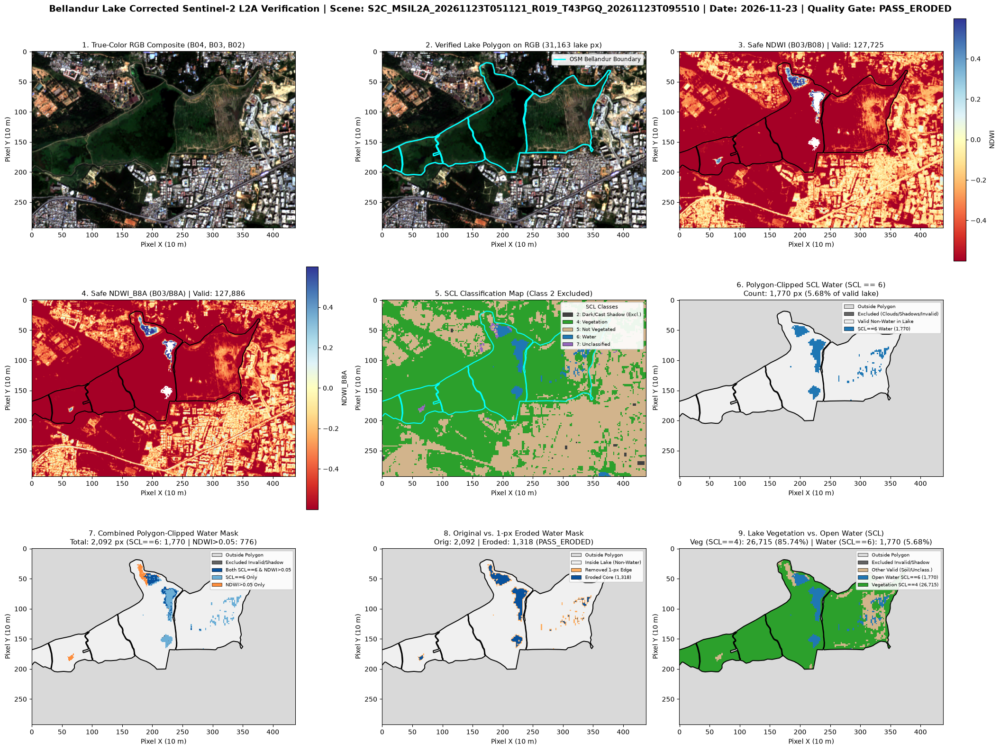

In [11]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm

def _plot_polygon_outline(ax, proj_geom, dst_transform, color="#00ffff", linewidth=1.6, label=None):
    """Overlay a reprojected GeoJSON Polygon/MultiPolygon boundary onto pixel axes."""
    inv_t = ~dst_transform
    gtype = proj_geom["type"]
    polys = [proj_geom["coordinates"]] if gtype == "Polygon" else proj_geom["coordinates"]
    first = True
    for poly in polys:
        for ring in poly:
            xs = np.array([pt[0] for pt in ring], dtype=np.float64)
            ys = np.array([pt[1] for pt in ring], dtype=np.float64)
            cols, rows = inv_t * (xs, ys)
            cols = cols - 0.5
            rows = rows - 0.5
            ax.plot(
                cols, rows,
                color=color,
                linewidth=linewidth,
                label=label if first else None,
            )
            first = False

# True-Color RGB with 2nd-98th percentile stretch
rgb_stack = np.stack([B04, B03, B02], axis=-1)
rgb_stretched = np.zeros_like(rgb_stack, dtype=np.float32)
for ch in range(3):
    channel = rgb_stack[:, :, ch]
    finite_vals = channel[np.isfinite(channel)]
    p2, p98 = np.percentile(finite_vals, [2, 98])
    normed = (channel - p2) / (p98 - p2 + 1e-6)
    rgb_stretched[:, :, ch] = np.clip(np.nan_to_num(normed, nan=0.0), 0.0, 1.0)

SCL_COLORS = {
    0: ("No Data", "#000000"),
    1: ("Saturated/Defective", "#ff0000"),
    2: ("Dark/Cast Shadow (Excl.)", "#404040"),
    3: ("Cloud Shadow (Excl.)", "#8b4513"),
    4: ("Vegetation", "#2ca02c"),
    5: ("Not Vegetated", "#d2b48c"),
    6: ("Water", "#1f77b4"),
    7: ("Unclassified", "#9467bd"),
    8: ("Cloud Med (Excl.)", "#b0b0b0"),
    9: ("Cloud High (Excl.)", "#ffffff"),
    10: ("Cirrus (Excl.)", "#87ceeb"),
    11: ("Snow/Ice (Excl.)", "#ff69b4"),
}
scl_cmap = ListedColormap([SCL_COLORS[k][1] for k in range(12)])
scl_norm = BoundaryNorm(np.arange(-0.5, 12.5, 1.0), scl_cmap.N)

h_px, w_px = target_shape

fig, axes = plt.subplots(3, 3, figsize=(21, 16), constrained_layout=True)
fig.suptitle(
    f"Bellandur Lake Corrected Sentinel-2 L2A Verification | Scene: {selected_item.id} | "
    f"Date: {selected_item.datetime.strftime('%Y-%m-%d')} | Quality Gate: {quality_gate_result['quality_flag']}",
    fontsize=14,
    fontweight="bold",
)

# Panel 1: True-Color RGB
ax = axes[0, 0]
ax.imshow(rgb_stretched)
ax.set_title("1. True-Color RGB Composite (B04, B03, B02)", fontsize=11)

# Panel 2: Verified Bellandur Lake Polygon Overlay on RGB
ax = axes[0, 1]
ax.imshow(rgb_stretched)
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="#00ffff", linewidth=2.0, label="OSM Bellandur Boundary")
ax.set_title(f"2. Verified Lake Polygon on RGB ({int(np.sum(inside_polygon)):,} lake px)", fontsize=11)
ax.legend(loc="upper right", fontsize=8.5, framealpha=0.9)

# Panel 3: NDWI (B03 / B08)
ax = axes[0, 2]
ndwi_norm = TwoSlopeNorm(vmin=-0.6, vcenter=0.0, vmax=0.6)
im_ndwi = ax.imshow(NDWI, cmap="RdYlBu", norm=ndwi_norm)
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="black", linewidth=1.4)
ax.set_title(f"3. Safe NDWI (B03/B08) | Valid: {int(np.sum(np.isfinite(NDWI))):,}", fontsize=11)
fig.colorbar(im_ndwi, ax=ax, fraction=0.046, pad=0.04, label="NDWI")

# Panel 4: NDWI_B8A (B03 / B8A)
ax = axes[1, 0]
im_ndwi8a = ax.imshow(NDWI_B8A, cmap="RdYlBu", norm=ndwi_norm)
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="black", linewidth=1.4)
ax.set_title(f"4. Safe NDWI_B8A (B03/B8A) | Valid: {int(np.sum(np.isfinite(NDWI_B8A))):,}", fontsize=11)
fig.colorbar(im_ndwi8a, ax=ax, fraction=0.046, pad=0.04, label="NDWI_B8A")

# Panel 5: SCL Classification Map
ax = axes[1, 1]
ax.imshow(scl, cmap=scl_cmap, norm=scl_norm, interpolation="nearest")
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="#00ffff", linewidth=1.5)
ax.set_title("5. SCL Classification Map (Class 2 Excluded)", fontsize=11)
present_classes = sorted(int(c) for c in np.unique(scl) if int(c) in SCL_COLORS)
ax.legend(
    handles=[
        mpatches.Patch(facecolor=SCL_COLORS[c][1], edgecolor="black", linewidth=0.5, label=f"{c}: {SCL_COLORS[c][0]}")
        for c in present_classes
    ],
    loc="upper right", fontsize=7.5, framealpha=0.92, title="SCL Classes", title_fontsize=8,
)

# Panel 6: Polygon-Clipped SCL Water Mask
ax = axes[1, 2]
scl_mask_vis = np.zeros(target_shape, dtype=np.uint8)
scl_mask_vis[inside_polygon & ~valid] = 1
scl_mask_vis[inside_polygon & valid] = 2
scl_mask_vis[scl_water_mask] = 3
ax.imshow(scl_mask_vis, cmap=ListedColormap(["#d9d9d9", "#636363", "#f0f0f0", "#1f77b4"]), vmin=0, vmax=3, interpolation="nearest")
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="black", linewidth=1.4)
ax.set_title(f"6. Polygon-Clipped SCL Water (SCL == 6)\nCount: {int(np.sum(scl_water_mask)):,} px ({open_water_pct:.2f}% of valid lake)", fontsize=11)
ax.legend(
    handles=[
        mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"),
        mpatches.Patch(facecolor="#636363", edgecolor="black", linewidth=0.5, label="Excluded (Clouds/Shadows/Invalid)"),
        mpatches.Patch(facecolor="#f0f0f0", edgecolor="black", linewidth=0.5, label="Valid Non-Water in Lake"),
        mpatches.Patch(facecolor="#1f77b4", edgecolor="black", linewidth=0.5, label=f"SCL==6 Water ({int(np.sum(scl_water_mask)):,})"),
    ],
    loc="upper right", fontsize=7.5, framealpha=0.92,
)

# Panel 7: Polygon-Clipped Combined Water Mask
ax = axes[2, 0]
comb_vis = np.zeros(target_shape, dtype=np.uint8)
comb_vis[inside_polygon & ~valid] = 1
comb_vis[inside_polygon & valid] = 2
comb_vis[scl_water_mask & ~ndwi_water_mask] = 3
comb_vis[ndwi_water_mask & ~scl_water_mask] = 4
comb_vis[scl_water_mask & ndwi_water_mask] = 5
ax.imshow(
    comb_vis,
    cmap=ListedColormap(["#d9d9d9", "#636363", "#f0f0f0", "#6baed6", "#fd8d3c", "#08519c"]),
    vmin=0, vmax=5, interpolation="nearest",
)
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="black", linewidth=1.4)
ax.set_title(
    f"7. Combined Polygon-Clipped Water Mask\n"
    f"Total: {int(np.sum(water_mask)):,} px (SCL==6: {int(np.sum(scl_water_mask)):,} | NDWI>0.05: {int(np.sum(ndwi_water_mask)):,})",
    fontsize=11,
)
ax.legend(
    handles=[
        mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"),
        mpatches.Patch(facecolor="#636363", edgecolor="black", linewidth=0.5, label="Excluded Invalid/Shadow"),
        mpatches.Patch(facecolor="#08519c", edgecolor="black", linewidth=0.5, label="Both SCL==6 & NDWI>0.05"),
        mpatches.Patch(facecolor="#6baed6", edgecolor="black", linewidth=0.5, label="SCL==6 Only"),
        mpatches.Patch(facecolor="#fd8d3c", edgecolor="black", linewidth=0.5, label="NDWI>0.05 Only"),
    ],
    loc="upper right", fontsize=7.5, framealpha=0.92,
)

# Panel 8: Original vs Eroded Water Mask
ax = axes[2, 1]
eroded_vis = np.zeros(target_shape, dtype=np.uint8)
eroded_vis[inside_polygon] = 1
eroded_vis[water_mask] = 2
eroded_vis[quality_gate_result["eroded_mask"]] = 3
ax.imshow(eroded_vis, cmap=ListedColormap(["#d9d9d9", "#f0f0f0", "#fdae61", "#08519c"]), vmin=0, vmax=3, interpolation="nearest")
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="black", linewidth=1.4)
ax.set_title(
    f"8. Original vs. 1-px Eroded Water Mask\n"
    f"Orig: {quality_gate_result['original_water_pixels']:,} | Eroded: {quality_gate_result['eroded_water_pixels']:,} ({quality_gate_result['quality_flag']})",
    fontsize=11,
)
ax.legend(
    handles=[
        mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"),
        mpatches.Patch(facecolor="#f0f0f0", edgecolor="black", linewidth=0.5, label="Inside Lake (Non-Water)"),
        mpatches.Patch(facecolor="#fdae61", edgecolor="black", linewidth=0.5, label="Removed 1-px Edge"),
        mpatches.Patch(facecolor="#08519c", edgecolor="black", linewidth=0.5, label=f"Eroded Core ({quality_gate_result['eroded_water_pixels']:,})"),
    ],
    loc="upper right", fontsize=7.5, framealpha=0.92,
)

# Panel 9: SCL Vegetation Classification Map Inside Polygon
ax = axes[2, 2]
veg_vis = np.zeros(target_shape, dtype=np.uint8)
veg_vis[inside_polygon & ~valid] = 1
veg_vis[inside_polygon & valid] = 2
veg_vis[inside_polygon & valid & (scl == 6)] = 3
veg_vis[inside_polygon & valid & (scl == 4)] = 4
ax.imshow(veg_vis, cmap=ListedColormap(["#d9d9d9", "#636363", "#d2b48c", "#1f77b4", "#2ca02c"]), vmin=0, vmax=4, interpolation="nearest")
_plot_polygon_outline(ax, bellandur_proj_geom, grid_info["ref_transform"], color="black", linewidth=1.4)
ax.set_title(
    f"9. Lake Vegetation vs. Open Water (SCL)\n"
    f"Veg (SCL==4): {veg_scl_px:,} ({veg_cover_pct:.2f}%) | Water (SCL==6): {open_water_scl_px:,} ({open_water_pct:.2f}%)",
    fontsize=11,
)
ax.legend(
    handles=[
        mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"),
        mpatches.Patch(facecolor="#636363", edgecolor="black", linewidth=0.5, label="Excluded Invalid/Shadow"),
        mpatches.Patch(facecolor="#d2b48c", edgecolor="black", linewidth=0.5, label="Other Valid (Soil/Unclass.)"),
        mpatches.Patch(facecolor="#1f77b4", edgecolor="black", linewidth=0.5, label=f"Open Water SCL==6 ({open_water_scl_px:,})"),
        mpatches.Patch(facecolor="#2ca02c", edgecolor="black", linewidth=0.5, label=f"Vegetation SCL==4 ({veg_scl_px:,})"),
    ],
    loc="upper right", fontsize=7.5, framealpha=0.92,
)

for ax in axes.ravel():
    ax.set_xlim(-0.5, w_px - 0.5)
    ax.set_ylim(h_px - 0.5, -0.5)
    ax.set_xlabel("Pixel X (10 m)")
    ax.set_ylabel("Pixel Y (10 m)")

output_png = (
    "bellandur_verification.png"
    if os.path.basename(os.getcwd()) == "ml"
    else os.path.join("ml", "bellandur_verification.png")
)
fig.savefig(output_png, dpi=150, bbox_inches="tight")
print(f"Saved updated verification figure to: {os.path.abspath(output_png)}")
plt.show()

## 12. Validation Checks and Summary Diagnostics

Automated PASS/FAIL validation across all 12 pipeline requirements using the retrieved Sentinel-2 L2A data and verified GeoJSON lake boundaries.

In [12]:
validation_checks = []

# 1. All four GeoJSON boundary files exist and are valid
all_geo_ok = len(loaded_polygons) == 4 and all(
    os.path.isfile(info["path"]) and info["geometry"]["type"] in ("Polygon", "MultiPolygon")
    for info in loaded_polygons.values()
)
validation_checks.append(("1. All four GeoJSON boundary files exist and are valid", all_geo_ok, f"{len(loaded_polygons)}/4 valid"))

# 2. Bellandur polygon overlaps intended study area
bell_overlap_ok = _bboxes_overlap(bellandur_poly["bbox_wgs84"], WATER_BODIES["bellandur"])
validation_checks.append(("2. Bellandur polygon overlaps intended study area", bell_overlap_ok, f"{int(np.sum(inside_polygon)):,} rasterized px"))

# 3. Polygon correctly transformed to satellite CRS
poly_crs_ok = (
    bellandur_proj_geom["type"] in ("Polygon", "MultiPolygon")
    and int(np.sum(inside_polygon)) > 0
    and str(grid_info["ref_crs"]) == native_band_metadata["B03"]["crs"]
)
validation_checks.append(("3. Polygon transformed to satellite CRS", poly_crs_ok, str(grid_info["ref_crs"])))

# 4. All nine required raster arrays are available
all_9_ok = all(b in band_stack for b in ALL_STACK_BANDS)
validation_checks.append(("4. All nine required raster arrays available", all_9_ok, f"{len(band_stack)}/9 bands"))

# 5. All arrays have matching dimensions
dims_ok = len({arr.shape for arr in band_stack.values()}) == 1 and scl.shape == target_shape
validation_checks.append(("5. All arrays have matching dimensions", dims_ok, str(target_shape)))

# 6. SCL remains categorical integer dtype
scl_cat_ok = np.issubdtype(scl.dtype, np.integer)
validation_checks.append(("6. SCL remains categorical integer dtype", scl_cat_ok, str(scl.dtype)))

# 7. Reflectance nodata is preserved as NaN
nodata_nan_ok = all(
    np.issubdtype(band_stack[b].dtype, np.floating)
    and bool(np.all(np.isnan(band_stack[b][raw_dn_stack[b] == 0])))
    and int(np.sum((raw_dn_stack[b] == 0) & np.isfinite(band_stack[b]))) == 0
    for b in SPECTRAL_BANDS
)
validation_checks.append(("7. Reflectance nodata preserved as NaN", nodata_nan_ok, "All DN == 0 -> np.nan"))

# 8. Safe-index calculations reject invalid reflectance
test_invalid_a = np.array([0.05, -0.002, 0.0, np.nan, 0.05], dtype=np.float32)
test_invalid_b = np.array([0.04, 0.04, 0.04, 0.04, -0.001], dtype=np.float32)
test_nd = safe_norm_diff(test_invalid_a, test_invalid_b)
test_rt = safe_ratio(test_invalid_a, test_invalid_b)
real_ndwi_rejects_nonpos = bool(
    np.all(np.isnan(NDWI[~(np.isfinite(B03) & np.isfinite(B08) & (B03 > 0) & (B08 > 0))]))
)
safe_idx_ok = (
    np.isfinite(test_nd[0]) and np.all(np.isnan(test_nd[1:]))
    and np.isfinite(test_rt[0]) and np.all(np.isnan(test_rt[1:]))
    and real_ndwi_rejects_nonpos
)
validation_checks.append(("8. Safe-index calculations reject invalid reflectance", safe_idx_ok, "Non-positive/NaN -> np.nan"))

# 9. No water pixels exist outside the lake polygon
no_outside_water_ok = int(np.sum(water_mask & ~inside_polygon)) == 0 and int(np.sum(quality_gate_result["selected_mask"] & ~inside_polygon)) == 0
validation_checks.append(("9. No water pixels outside lake polygon", no_outside_water_ok, "0 outside-polygon water px"))

# 10. SCL class 2 is excluded from valid pixels
class2_excl_ok = int(np.sum(valid & (scl == 2))) == 0 and (2 in INVALID_SCL_CLASSES)
validation_checks.append(("10. SCL class 2 excluded from valid pixels", class2_excl_ok, f"{int(np.sum(scl == 2))} class-2 px in window excluded"))

# 11. Water-pixel quality gate works correctly
gate_empty = apply_water_pixel_quality_gate(np.zeros((10, 10), dtype=bool), valid_lake_mask=np.zeros((10, 10), dtype=bool))
gate_low = apply_water_pixel_quality_gate(np.pad(np.ones((5, 5), dtype=bool), 2), valid_lake_mask=np.ones((9, 9), dtype=bool), min_pixels=200)
gate_fallback = apply_water_pixel_quality_gate(water_mask, valid_lake_mask=valid_lake, min_pixels=int(quality_gate_result["eroded_water_pixels"]) + 1)
qgate_ok = (
    quality_gate_result["quality_flag"] in ("PASS_ERODED", "PASS_FALLBACK_UNERODED", "LOW_WATER_PIXELS", "INVALID_OR_INSUFFICIENT_DATA")
    and gate_empty["quality_flag"] == "INVALID_OR_INSUFFICIENT_DATA"
    and gate_low["quality_flag"] == "LOW_WATER_PIXELS"
    and (gate_fallback["quality_flag"] == "PASS_FALLBACK_UNERODED" if quality_gate_result["original_water_pixels"] > quality_gate_result["eroded_water_pixels"] else True)
)
validation_checks.append(("11. Water-pixel quality gate works correctly", qgate_ok, quality_gate_result["quality_flag"]))

# 12. Open-water and vegetation percentages use the correct denominator (valid_lake_pixels)
denom_ok = (
    valid_lake_pixels > 0
    and abs(open_water_pct - (open_water_scl_px / valid_lake_pixels * 100.0)) < 1e-9
    and abs(veg_cover_pct - (veg_scl_px / valid_lake_pixels * 100.0)) < 1e-9
)
validation_checks.append(("12. Open-water & vegetation use valid_lake_pixels denominator", denom_ok, f"denom={valid_lake_pixels:,}"))

print("=== 12-Point Pipeline Validation Checks ===")
for label, passed, detail in validation_checks:
    print(f"[{'PASS' if passed else 'FAIL'}] {label}: {detail}")

band_stats_rows = []
for b in SPECTRAL_BANDS:
    arr = band_stack[b]
    band_stats_rows.append({
        "Band": b,
        "Min": round(float(np.nanmin(arr)), 6),
        "Max": round(float(np.nanmax(arr)), 6),
        "Mean": round(float(np.nanmean(arr)), 6),
        "NaN_Count": int(np.sum(np.isnan(arr))),
        "Negative_Count": int(np.sum(np.isfinite(arr) & (arr < 0))),
    })
print("\n=== Spectral Band Reflectance Summary Statistics (All 8 Spectral Bands) ===")
print(pd.DataFrame(band_stats_rows).to_string(index=False))

if not all(c[1] for c in validation_checks):
    raise AssertionError("One or more validation checks failed!")

=== 12-Point Pipeline Validation Checks ===
[PASS] 1. All four GeoJSON boundary files exist and are valid: 4/4 valid
[PASS] 2. Bellandur polygon overlaps intended study area: 31,163 rasterized px
[PASS] 3. Polygon transformed to satellite CRS: EPSG:32643
[PASS] 4. All nine required raster arrays available: 9/9 bands
[PASS] 5. All arrays have matching dimensions: (293, 438)
[PASS] 6. SCL remains categorical integer dtype: int16
[PASS] 7. Reflectance nodata preserved as NaN: All DN == 0 -> np.nan
[PASS] 8. Safe-index calculations reject invalid reflectance: Non-positive/NaN -> np.nan
[PASS] 9. No water pixels outside lake polygon: 0 outside-polygon water px
[PASS] 10. SCL class 2 excluded from valid pixels: 236 class-2 px in window excluded
[PASS] 11. Water-pixel quality gate works correctly: PASS_ERODED
[PASS] 12. Open-water & vegetation use valid_lake_pixels denominator: denom=31,157

=== Spectral Band Reflectance Summary Statistics (All 8 Spectral Bands) ===
Band       Min      Max   

## 13. Single-Scene Verification for Hussain Sagar, Yamuna Okhla, and Sukhna Lake

Before running multi-date batch extraction, we apply the exact same 9-band aligned stack, polygon clipping (including `yamuna_okhla` interior island rings), safe spectral index calculations, revised water masking, open-water/vegetation accounting, quality gate, and 9-panel visual verification to the remaining three study locations:
1. **Hussain Sagar** (`hussain_sagar`)
2. **Yamuna Okhla** (`yamuna_okhla`) — including explicit verification that inner island rings remain excluded (`inside_polygon == False`) and selected pixels capture mid-channel water rather than bridges, banks, or shadows
3. **Sukhna Lake** (`sukhna`)

Each lake uses `union(SPEC_bbox, polygon_bbox)` padded by `0.002°` for the raster read window to prevent edge clipping while keeping the verified lake GeoJSON polygon as the strict spatial clipping mask.


==================== HUSSAIN_SAGAR SINGLE-SCENE VERIFICATION ====================
Scenes found: 80 | Selected: S2B_MSIL2A_20260512T050649_R019_T44QKE_20260512T085408 (2026-05-12)
Tile cloud: 0.0014% | Lake non-nodata: 100.00% | Lake cloud/shadow: 0.00%
Processing baseline: 05.12 | Aligned shape: (427, 442) | Lake px: 45,396
Unclipped counts -> SCL==6: 43,028 | NDWI>0.0: 18,505 | NDWI>0.1: 9,633
Clipped counts   -> SCL==6: 40,947 | NDWI>0.05: 13,817 | Combined: 41,059
Open water (SCL==6): 90.20% (40,947/45,396) | Veg (SCL==4): 5.94% (2,697/45,396)
Quality Gate: eroded=39,661, selected=39,661, flag=PASS_ERODED, reason=None
Inner island rings: 1 | Overlap inside_polygon & holes (must be 0): 0


Saved verification figure: C:\Users\somya\OneDrive\Desktop\miniproject\ml\hussain_sagar_verification.png


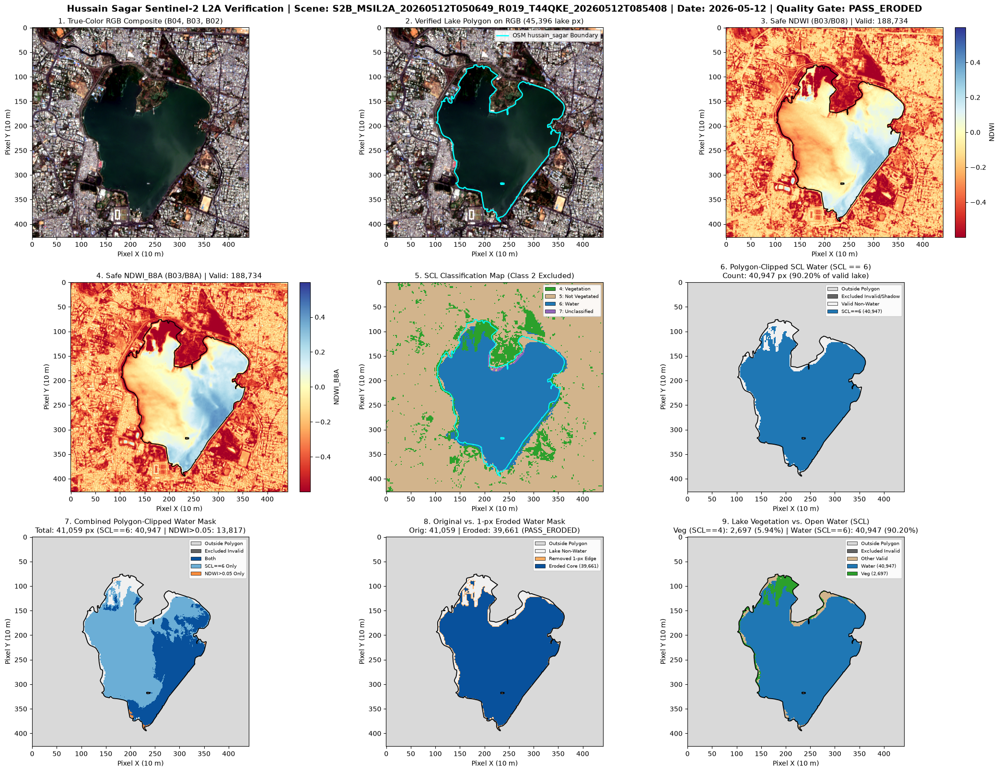


==================== YAMUNA_OKHLA SINGLE-SCENE VERIFICATION ====================
Scenes found: 59 | Selected: S2B_MSIL2A_20261124T053149_R105_T43RGM_20261124T073301 (2026-11-24)
Tile cloud: 0.0005% | Lake non-nodata: 100.00% | Lake cloud/shadow: 0.00%
Processing baseline: 05.13 | Aligned shape: (412, 341) | Lake px: 26,888
Unclipped counts -> SCL==6: 32,760 | NDWI>0.0: 25,708 | NDWI>0.1: 21,996
Clipped counts   -> SCL==6: 17,810 | NDWI>0.05: 13,465 | Combined: 18,137
Open water (SCL==6): 66.24% (17,810/26,888) | Veg (SCL==4): 21.51% (5,784/26,888)
Quality Gate: eroded=15,643, selected=15,643, flag=PASS_ERODED, reason=None
Inner island rings: 8 | Overlap inside_polygon & holes (must be 0): 0


Saved verification figure: C:\Users\somya\OneDrive\Desktop\miniproject\ml\yamuna_okhla_verification.png


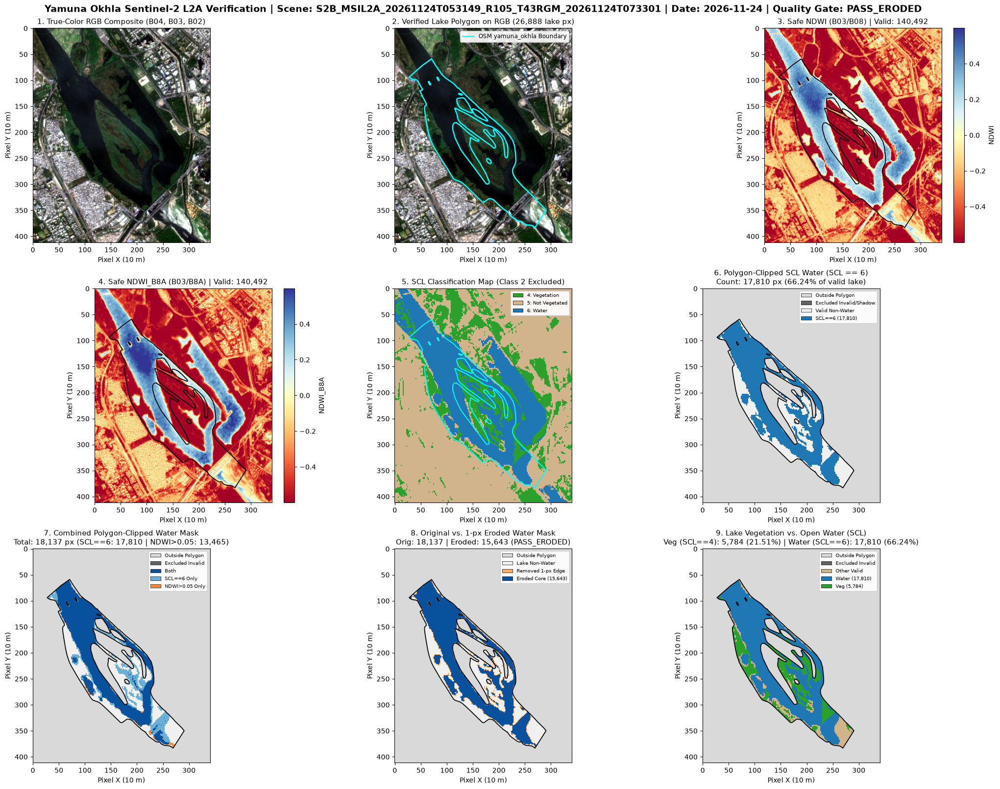


==================== SUKHNA SINGLE-SCENE VERIFICATION ====================
Scenes found: 59 | Selected: S2A_MSIL2A_20261111T053231_R105_T43RFQ_20261111T102104 (2026-11-11)
Tile cloud: 0.0011% | Lake non-nodata: 100.00% | Lake cloud/shadow: 0.00%
Processing baseline: 05.13 | Aligned shape: (262, 350) | Lake px: 13,602
Unclipped counts -> SCL==6: 13,832 | NDWI>0.0: 13,279 | NDWI>0.1: 12,995
Clipped counts   -> SCL==6: 12,855 | NDWI>0.05: 12,915 | Combined: 13,193
Open water (SCL==6): 94.51% (12,855/13,602) | Veg (SCL==4): 1.32% (179/13,602)
Quality Gate: eroded=12,415, selected=12,415, flag=PASS_ERODED, reason=None
Inner island rings: 4 | Overlap inside_polygon & holes (must be 0): 0


Saved verification figure: C:\Users\somya\OneDrive\Desktop\miniproject\ml\sukhna_verification.png


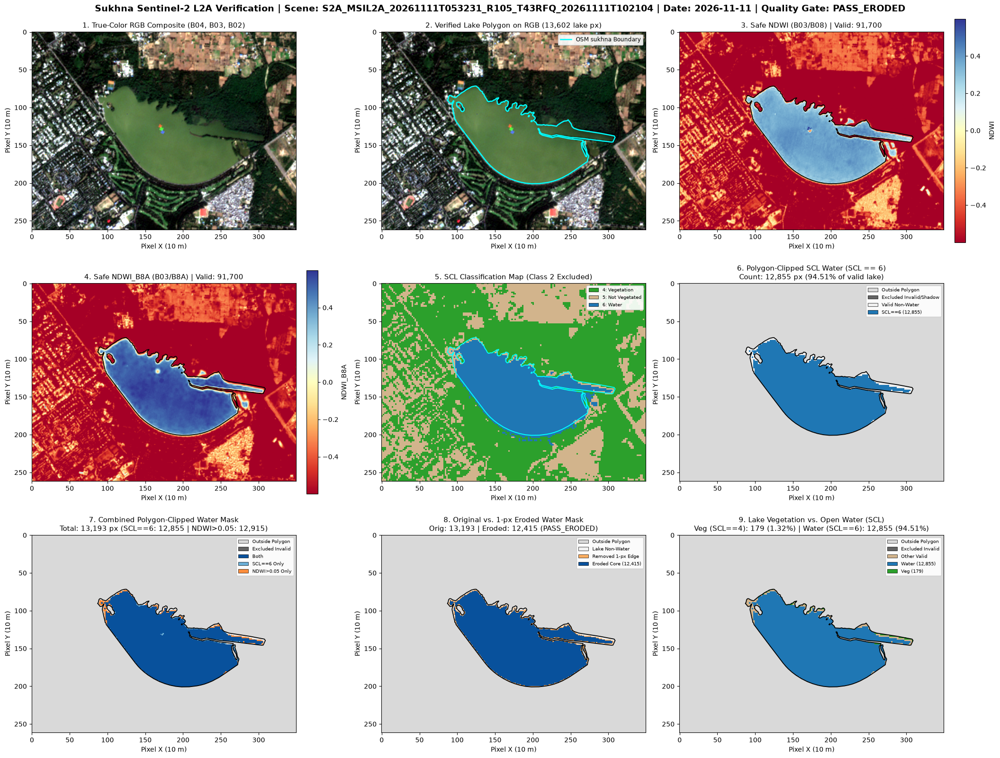


=== Remaining Three Lakes Verification Summary ===
      lake_id                                               scene_id       date      shape  lake_px  comb_water_px  eroded_water_px  selected_water_px quality_flag  open_water_pct  veg_cover_pct  inner_ring_overlap_px
hussain_sagar S2B_MSIL2A_20260512T050649_R019_T44QKE_20260512T085408 2026-05-12 (427, 442)    45396          41059            39661              39661  PASS_ERODED           90.20           5.94                      0
 yamuna_okhla S2B_MSIL2A_20261124T053149_R105_T43RGM_20261124T073301 2026-11-24 (412, 341)    26888          18137            15643              15643  PASS_ERODED           66.24          21.51                      0
       sukhna S2A_MSIL2A_20261111T053231_R105_T43RFQ_20261111T102104 2026-11-11 (262, 350)    13602          13193            12415              12415  PASS_ERODED           94.51           1.32                      0


In [13]:
def compute_read_bbox(spec_bbox, poly_bbox, pad_deg=0.002):
    """Compute union(SPEC_bbox, polygon_bbox) padded by pad_deg to avoid edge clipping."""
    return [
        max(-180.0, min(spec_bbox[0], poly_bbox[0]) - pad_deg),
        max(-90.0, min(spec_bbox[1], poly_bbox[1]) - pad_deg),
        min(180.0, max(spec_bbox[2], poly_bbox[2]) + pad_deg),
        min(90.0, max(spec_bbox[3], poly_bbox[3]) + pad_deg),
    ]


def select_clearest_recent_scene(catalog_client, spec_bbox, poly_info, datetime_range="2025-05-01/2026-11-24", max_cloud=20, top_k=12):
    """Search and select the clearest recent valid Sentinel-2 L2A scene inside the lake polygon."""
    search_obj = catalog_client.search(
        collections=["sentinel-2-l2a"],
        bbox=spec_bbox,
        datetime=datetime_range,
        query={"eo:cloud_cover": {"lt": max_cloud}},
        max_items=80,
    )
    found_items = list(search_obj.items())
    if not found_items:
        raise RuntimeError(f"No scenes found for bbox={spec_bbox} in {datetime_range}.")

    cands = sorted(
        found_items,
        key=lambda it: (round(float(it.properties.get("eo:cloud_cover", 100.0)), 2), -it.datetime.timestamp()),
    )[:top_k]

    passing = []
    for cand in cands:
        if not all(b in cand.assets for b in REQUIRED_ASSETS):
            continue
        with rasterio.open(cand.assets["SCL"].href) as src:
            proj_bb = transform_bounds("EPSG:4326", src.crs, *compute_read_bbox(spec_bbox, poly_info["bbox_wgs84"], 0.002))
            win = from_bounds(*proj_bb, transform=src.transform)
            col_s, row_s = int(np.floor(win.col_off)), int(np.floor(win.row_off))
            col_e, row_e = int(np.ceil(win.col_off + win.width)), int(np.ceil(win.row_off + win.height))
            w_int = Window(col_s, row_s, col_e - col_s, row_e - row_s)
            scl_win = src.read(1, window=w_int, boundless=True, fill_value=0)
            w_tf = src.window_transform(w_int)
            in_poly_native, _ = rasterize_lake_polygon(poly_info, src.crs, w_tf, scl_win.shape)
        if np.sum(in_poly_native) == 0:
            continue
        scl_lake = scl_win[in_poly_native]
        non_nodata = scl_lake != 0
        non_nodata_pct = float(np.mean(non_nodata) * 100.0)
        cloud_shadow_pct = float(np.mean(np.isin(scl_lake[non_nodata], list(CLOUD_SHADOW_CLASSES))) * 100.0) if np.any(non_nodata) else 100.0
        if non_nodata_pct > 95.0 and cloud_shadow_pct < 10.0:
            passing.append((round(cloud_shadow_pct, 2), -round(non_nodata_pct, 2), -cand.datetime.timestamp(), cand, non_nodata_pct, cloud_shadow_pct))

    if not passing:
        raise RuntimeError(f"No candidate satisfied >95% non-nodata and <10% local cloud/shadow inside {poly_info['lake_id']}.")
    passing.sort(key=lambda x: (x[0], x[1], x[2]))
    _, _, _, best_item, nn_pct, cs_pct = passing[0]
    return best_item, len(found_items), nn_pct, cs_pct


def verify_lake_single_scene(lake_id, catalog_client, loaded_polys, spec_bboxes, out_dir=None):
    """Run full single-scene verification, visual plot, and automated checks for a study lake."""
    poly_info = loaded_polys[lake_id]
    spec_bbox = spec_bboxes[lake_id]
    read_bbox = compute_read_bbox(spec_bbox, poly_info["bbox_wgs84"], pad_deg=0.002)

    item, n_found, nn_pct, cs_pct = select_clearest_recent_scene(catalog_client, spec_bbox, poly_info)
    b_stack, raw_stack, g_info = load_aligned_band_stack(item, read_bbox)
    t_shape = g_info["target_shape"]
    in_poly, proj_geom = rasterize_lake_polygon(poly_info, g_info["ref_crs"], g_info["ref_transform"], t_shape)

    b02, b03, b04 = b_stack["B02"], b_stack["B03"], b_stack["B04"]
    b05, b08, b8a, scl_arr = b_stack["B05"], b_stack["B08"], b_stack["B8A"], b_stack["SCL"]

    ndwi = safe_norm_diff(b03, b08)
    ndwi_b8a = safe_norm_diff(b03, b8a)
    ndci = safe_norm_diff(b05, b04)
    ndti = safe_norm_diff(b04, b03)
    two_bda = safe_ratio(b05, b04)

    v_mask = (~np.isin(scl_arr, INVALID_SCL_CLASSES)) & np.isfinite(b03) & np.isfinite(b08)
    scl_w = in_poly & v_mask & (scl_arr == 6)
    ndwi_w = in_poly & v_mask & (ndwi > 0.05)
    comb_w = in_poly & v_mask & ((scl_arr == 6) | (ndwi > 0.05))

    orig_v = (~np.isin(scl_arr, [0, 1, 3, 8, 9, 10])) & np.isfinite(b03) & np.isfinite(b08)
    orig_scl_cnt = int(np.sum(orig_v & (scl_arr == 6)))
    orig_ndwi00_cnt = int(np.sum(orig_v & (ndwi > 0.0)))
    orig_ndwi01_cnt = int(np.sum(orig_v & (ndwi > 0.1)))

    v_lake = in_poly & v_mask
    v_lake_px = int(np.sum(v_lake))
    ow_px = int(np.sum(v_lake & (scl_arr == 6)))
    veg_px = int(np.sum(v_lake & (scl_arr == 4)))
    ow_pct = (ow_px / v_lake_px * 100.0) if v_lake_px > 0 else 0.0
    veg_pct = (veg_px / v_lake_px * 100.0) if v_lake_px > 0 else 0.0

    q_res = apply_water_pixel_quality_gate(comb_w, valid_lake_mask=v_lake, min_pixels=200)

    # Special inner-ring check (critical for yamuna_okhla islands)
    inner_ring_overlap_px = 0
    geom = poly_info["geometry"]
    hole_polys = []
    if geom["type"] == "Polygon" and len(geom["coordinates"]) > 1:
        hole_polys = [{"type": "Polygon", "coordinates": [r]} for r in geom["coordinates"][1:]]
    elif geom["type"] == "MultiPolygon":
        for poly in geom["coordinates"]:
            if len(poly) > 1:
                hole_polys.extend({"type": "Polygon", "coordinates": [r]} for r in poly[1:])
    if hole_polys:
        proj_holes = [transform_geom("EPSG:4326", str(g_info["ref_crs"]), hp) for hp in hole_polys]
        holes_rast = rasterize([(ph, 1) for ph in proj_holes], out_shape=t_shape, transform=g_info["ref_transform"], fill=0, dtype=np.uint8).astype(bool)
        inner_ring_overlap_px = int(np.sum(in_poly & holes_rast))

    print(f"\n==================== {lake_id.upper()} SINGLE-SCENE VERIFICATION ====================")
    print(f"Scenes found: {n_found} | Selected: {item.id} ({item.datetime.strftime('%Y-%m-%d')})")
    print(f"Tile cloud: {item.properties.get('eo:cloud_cover'):.4f}% | Lake non-nodata: {nn_pct:.2f}% | Lake cloud/shadow: {cs_pct:.2f}%")
    print(f"Processing baseline: {item.properties.get('s2:processing_baseline')} | Aligned shape: {t_shape} | Lake px: {int(np.sum(in_poly)):,}")
    print(f"Unclipped counts -> SCL==6: {orig_scl_cnt:,} | NDWI>0.0: {orig_ndwi00_cnt:,} | NDWI>0.1: {orig_ndwi01_cnt:,}")
    print(f"Clipped counts   -> SCL==6: {int(np.sum(scl_w)):,} | NDWI>0.05: {int(np.sum(ndwi_w)):,} | Combined: {int(np.sum(comb_w)):,}")
    print(f"Open water (SCL==6): {ow_pct:.2f}% ({ow_px:,}/{v_lake_px:,}) | Veg (SCL==4): {veg_pct:.2f}% ({veg_px:,}/{v_lake_px:,})")
    print(f"Quality Gate: eroded={q_res['eroded_water_pixels']:,}, selected={q_res['selected_water_pixels']:,}, flag={q_res['quality_flag']}, reason={q_res['fallback_reason']}")
    if hole_polys:
        print(f"Inner island rings: {len(hole_polys)} | Overlap inside_polygon & holes (must be 0): {inner_ring_overlap_px}")

    # Plot 9-panel figure
    rgb_s = np.stack([b04, b03, b02], axis=-1)
    rgb_st = np.zeros_like(rgb_s, dtype=np.float32)
    for ch in range(3):
        c_arr = rgb_s[:, :, ch]
        fin_v = c_arr[np.isfinite(c_arr)]
        p2, p98 = np.percentile(fin_v, [2, 98])
        rgb_st[:, :, ch] = np.clip(np.nan_to_num((c_arr - p2) / (p98 - p2 + 1e-6), nan=0.0), 0.0, 1.0)

    h_p, w_p = t_shape
    fig, axes = plt.subplots(3, 3, figsize=(21, 16), constrained_layout=True)
    fig.suptitle(
        f"{lake_id.replace('_', ' ').title()} Sentinel-2 L2A Verification | Scene: {item.id} | "
        f"Date: {item.datetime.strftime('%Y-%m-%d')} | Quality Gate: {q_res['quality_flag']}",
        fontsize=14, fontweight="bold",
    )

    axes[0, 0].imshow(rgb_st)
    axes[0, 0].set_title("1. True-Color RGB Composite (B04, B03, B02)", fontsize=11)

    axes[0, 1].imshow(rgb_st)
    _plot_polygon_outline(axes[0, 1], proj_geom, g_info["ref_transform"], color="#00ffff", linewidth=1.8, label=f"OSM {lake_id} Boundary")
    axes[0, 1].set_title(f"2. Verified Lake Polygon on RGB ({int(np.sum(in_poly)):,} lake px)", fontsize=11)
    axes[0, 1].legend(loc="upper right", fontsize=8.5, framealpha=0.9)

    im3 = axes[0, 2].imshow(ndwi, cmap="RdYlBu", norm=ndwi_norm)
    _plot_polygon_outline(axes[0, 2], proj_geom, g_info["ref_transform"], color="black", linewidth=1.3)
    axes[0, 2].set_title(f"3. Safe NDWI (B03/B08) | Valid: {int(np.sum(np.isfinite(ndwi))):,}", fontsize=11)
    fig.colorbar(im3, ax=axes[0, 2], fraction=0.046, pad=0.04, label="NDWI")

    im4 = axes[1, 0].imshow(ndwi_b8a, cmap="RdYlBu", norm=ndwi_norm)
    _plot_polygon_outline(axes[1, 0], proj_geom, g_info["ref_transform"], color="black", linewidth=1.3)
    axes[1, 0].set_title(f"4. Safe NDWI_B8A (B03/B8A) | Valid: {int(np.sum(np.isfinite(ndwi_b8a))):,}", fontsize=11)
    fig.colorbar(im4, ax=axes[1, 0], fraction=0.046, pad=0.04, label="NDWI_B8A")

    axes[1, 1].imshow(scl_arr, cmap=scl_cmap, norm=scl_norm, interpolation="nearest")
    _plot_polygon_outline(axes[1, 1], proj_geom, g_info["ref_transform"], color="#00ffff", linewidth=1.4)
    axes[1, 1].set_title("5. SCL Classification Map (Class 2 Excluded)", fontsize=11)
    pres = sorted(int(c) for c in np.unique(scl_arr) if int(c) in SCL_COLORS)
    axes[1, 1].legend(handles=[mpatches.Patch(facecolor=SCL_COLORS[c][1], edgecolor="black", linewidth=0.5, label=f"{c}: {SCL_COLORS[c][0]}") for c in pres], loc="upper right", fontsize=7.5, framealpha=0.92)

    m6 = np.zeros(t_shape, dtype=np.uint8)
    m6[in_poly & ~v_mask] = 1; m6[in_poly & v_mask] = 2; m6[scl_w] = 3
    axes[1, 2].imshow(m6, cmap=ListedColormap(["#d9d9d9", "#636363", "#f0f0f0", "#1f77b4"]), vmin=0, vmax=3, interpolation="nearest")
    _plot_polygon_outline(axes[1, 2], proj_geom, g_info["ref_transform"], color="black", linewidth=1.3)
    axes[1, 2].set_title(f"6. Polygon-Clipped SCL Water (SCL == 6)\nCount: {int(np.sum(scl_w)):,} px ({ow_pct:.2f}% of valid lake)", fontsize=11)
    axes[1, 2].legend(handles=[mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"), mpatches.Patch(facecolor="#636363", edgecolor="black", linewidth=0.5, label="Excluded Invalid/Shadow"), mpatches.Patch(facecolor="#f0f0f0", edgecolor="black", linewidth=0.5, label="Valid Non-Water"), mpatches.Patch(facecolor="#1f77b4", edgecolor="black", linewidth=0.5, label=f"SCL==6 ({int(np.sum(scl_w)):,})")], loc="upper right", fontsize=7.5, framealpha=0.92)

    m7 = np.zeros(t_shape, dtype=np.uint8)
    m7[in_poly & ~v_mask] = 1; m7[in_poly & v_mask] = 2; m7[scl_w & ~ndwi_w] = 3; m7[ndwi_w & ~scl_w] = 4; m7[scl_w & ndwi_w] = 5
    axes[2, 0].imshow(m7, cmap=ListedColormap(["#d9d9d9", "#636363", "#f0f0f0", "#6baed6", "#fd8d3c", "#08519c"]), vmin=0, vmax=5, interpolation="nearest")
    _plot_polygon_outline(axes[2, 0], proj_geom, g_info["ref_transform"], color="black", linewidth=1.3)
    axes[2, 0].set_title(f"7. Combined Polygon-Clipped Water Mask\nTotal: {int(np.sum(comb_w)):,} px (SCL==6: {int(np.sum(scl_w)):,} | NDWI>0.05: {int(np.sum(ndwi_w)):,})", fontsize=11)
    axes[2, 0].legend(handles=[mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"), mpatches.Patch(facecolor="#636363", edgecolor="black", linewidth=0.5, label="Excluded Invalid"), mpatches.Patch(facecolor="#08519c", edgecolor="black", linewidth=0.5, label="Both"), mpatches.Patch(facecolor="#6baed6", edgecolor="black", linewidth=0.5, label="SCL==6 Only"), mpatches.Patch(facecolor="#fd8d3c", edgecolor="black", linewidth=0.5, label="NDWI>0.05 Only")], loc="upper right", fontsize=7.5, framealpha=0.92)

    m8 = np.zeros(t_shape, dtype=np.uint8)
    m8[in_poly] = 1; m8[comb_w] = 2; m8[q_res["eroded_mask"]] = 3
    axes[2, 1].imshow(m8, cmap=ListedColormap(["#d9d9d9", "#f0f0f0", "#fdae61", "#08519c"]), vmin=0, vmax=3, interpolation="nearest")
    _plot_polygon_outline(axes[2, 1], proj_geom, g_info["ref_transform"], color="black", linewidth=1.3)
    axes[2, 1].set_title(f"8. Original vs. 1-px Eroded Water Mask\nOrig: {q_res['original_water_pixels']:,} | Eroded: {q_res['eroded_water_pixels']:,} ({q_res['quality_flag']})", fontsize=11)
    axes[2, 1].legend(handles=[mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"), mpatches.Patch(facecolor="#f0f0f0", edgecolor="black", linewidth=0.5, label="Lake Non-Water"), mpatches.Patch(facecolor="#fdae61", edgecolor="black", linewidth=0.5, label="Removed 1-px Edge"), mpatches.Patch(facecolor="#08519c", edgecolor="black", linewidth=0.5, label=f"Eroded Core ({q_res['eroded_water_pixels']:,})")], loc="upper right", fontsize=7.5, framealpha=0.92)

    m9 = np.zeros(t_shape, dtype=np.uint8)
    m9[in_poly & ~v_mask] = 1; m9[in_poly & v_mask] = 2; m9[in_poly & v_mask & (scl_arr == 6)] = 3; m9[in_poly & v_mask & (scl_arr == 4)] = 4
    axes[2, 2].imshow(m9, cmap=ListedColormap(["#d9d9d9", "#636363", "#d2b48c", "#1f77b4", "#2ca02c"]), vmin=0, vmax=4, interpolation="nearest")
    _plot_polygon_outline(axes[2, 2], proj_geom, g_info["ref_transform"], color="black", linewidth=1.3)
    axes[2, 2].set_title(f"9. Lake Vegetation vs. Open Water (SCL)\nVeg (SCL==4): {veg_px:,} ({veg_pct:.2f}%) | Water (SCL==6): {ow_px:,} ({ow_pct:.2f}%)", fontsize=11)
    axes[2, 2].legend(handles=[mpatches.Patch(facecolor="#d9d9d9", edgecolor="black", linewidth=0.5, label="Outside Polygon"), mpatches.Patch(facecolor="#636363", edgecolor="black", linewidth=0.5, label="Excluded Invalid"), mpatches.Patch(facecolor="#d2b48c", edgecolor="black", linewidth=0.5, label="Other Valid"), mpatches.Patch(facecolor="#1f77b4", edgecolor="black", linewidth=0.5, label=f"Water ({ow_px:,})"), mpatches.Patch(facecolor="#2ca02c", edgecolor="black", linewidth=0.5, label=f"Veg ({veg_px:,})")], loc="upper right", fontsize=7.5, framealpha=0.92)

    for ax in axes.ravel():
        ax.set_xlim(-0.5, w_p - 0.5)
        ax.set_ylim(h_p - 0.5, -0.5)
        ax.set_xlabel("Pixel X (10 m)")
        ax.set_ylabel("Pixel Y (10 m)")

    if out_dir is None:
        out_png = f"{lake_id}_verification.png" if os.path.basename(os.getcwd()) == "ml" else os.path.join("ml", f"{lake_id}_verification.png")
    else:
        out_png = os.path.join(out_dir, f"{lake_id}_verification.png")
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    print(f"Saved verification figure: {os.path.abspath(out_png)}")
    plt.show()

    assert len({arr.shape for arr in b_stack.values()}) == 1
    assert np.issubdtype(scl_arr.dtype, np.integer)
    assert int(np.sum(comb_w & ~in_poly)) == 0
    assert int(np.sum(v_mask & (scl_arr == 2))) == 0
    assert inner_ring_overlap_px == 0
    return {
        "lake_id": lake_id,
        "scene_id": item.id,
        "date": item.datetime.strftime("%Y-%m-%d"),
        "shape": t_shape,
        "lake_px": int(np.sum(in_poly)),
        "comb_water_px": int(np.sum(comb_w)),
        "eroded_water_px": q_res["eroded_water_pixels"],
        "selected_water_px": q_res["selected_water_pixels"],
        "quality_flag": q_res["quality_flag"],
        "open_water_pct": round(ow_pct, 2),
        "veg_cover_pct": round(veg_pct, 2),
        "inner_ring_overlap_px": inner_ring_overlap_px,
    }


remaining_verif = []
for lid in ["hussain_sagar", "yamuna_okhla", "sukhna"]:
    res = verify_lake_single_scene(lid, catalog, loaded_polygons, WATER_BODIES)
    remaining_verif.append(res)

print("\n=== Remaining Three Lakes Verification Summary ===")
print(pd.DataFrame(remaining_verif).to_string(index=False))

## 14. Multi-Date Sentinel-2 L2A Batch Extraction, CSV & Spatial Patch Export

This stage executes multi-date ingestion across all four study water bodies (`bellandur`, `hussain_sagar`, `yamuna_okhla`, `sukhna`) over `2024-06-01` through `2026-11-24` (`eo:cloud_cover < 20%`):
- **Read window:** `union(SPEC_bbox, polygon_bbox)` padded by `0.002°`, clipped strictly by the verified lake GeoJSON polygon.
- **Deduplication & local QC:** Deduplicate overlapping same-date MGRS tiles (preferring primary lake tile / lowest tile cloud cover), reject scenes with `< 95%` non-nodata lake coverage, `> 15%` local cloud/shadow pixels inside the lake polygon, or `< 100` selected water pixels / quality-gate failure.
- **Seasonal balancing:** Target 25–35 clean scenes per lake distributed evenly across **Pre-monsoon** (Mar–May), **Monsoon** (Jun–Sep), and **Post-monsoon** (Oct–Feb).
- **Outputs:**
  - `data/processed/sentinel_timeseries.csv` (one row per `(lake_id, date)`, median and p90 over the eroded water core)
  - `data/processed/sentinel_patches/{lake_id}.npz` (compressed `(T, 9, 64, 64)` `float32` tensors with `dates` and `bounds`)

In [14]:
import os
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from rasterio.transform import from_bounds as transform_from_bounds

# Speed up remote Cloud-Optimized GeoTIFF streaming
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"
os.environ["GDAL_HTTP_MULTIRANGE"] = "YES"

BATCH_DATETIME = "2024-06-01/2026-11-24"
TARGET_SCENES_PER_LAKE = 32  # Within 25-35 target
PRIMARY_TILES = {
    "bellandur": "43PGQ",
    "hussain_sagar": "44QKE",
    "yamuna_okhla": "43RGM",
    "sukhna": "43RFQ",
}
CANONICAL_CRS = {
    "bellandur": "EPSG:32643",
    "hussain_sagar": "EPSG:32644",
    "yamuna_okhla": "EPSG:32643",
    "sukhna": "EPSG:32643",
}
CSV_SPECTRAL_FEATURES = [
    "B02", "B03", "B04", "B05", "B06", "B07", "B8A",
    "NDWI", "NDWI_B8A", "NDCI", "NDTI", "2BDA",
]
PATCH_CHANNELS = ["B02", "B03", "B04", "B05", "B06", "B8A", "NDCI", "NDTI", "water_mask"]

PROCESSED_DIR = (
    os.path.join("..", "data", "processed")
    if os.path.basename(os.getcwd()) == "ml"
    else os.path.join("data", "processed")
)
PATCHES_DIR = os.path.join(PROCESSED_DIR, "sentinel_patches")
os.makedirs(PATCHES_DIR, exist_ok=True)
CSV_OUT_PATH = os.path.join(PROCESSED_DIR, "sentinel_timeseries.csv")


def get_indian_season(month_int):
    if month_int in (6, 7, 8, 9):
        return "Monsoon"
    if month_int in (3, 4, 5):
        return "Pre-monsoon"
    return "Post-monsoon"


def evenly_spaced_indices(n_total, k_pick):
    if k_pick >= n_total:
        return list(range(n_total))
    if k_pick <= 0:
        return []
    if k_pick == 1:
        return [n_total // 2]
    return sorted(set(int(round(i * (n_total - 1) / (k_pick - 1))) for i in range(k_pick)))


def prescreen_scl_scene(item, lake_id, poly_info, read_bbox):
    """Fast SCL-only local cloud and coverage screening inside the lake polygon."""
    if not all(b in item.assets for b in REQUIRED_ASSETS):
        return False, "MISSING_REQUIRED_ASSETS", None
    try:
        with rasterio.open(item.assets["SCL"].href) as src:
            proj_bb = transform_bounds("EPSG:4326", src.crs, *read_bbox)
            win = from_bounds(*proj_bb, transform=src.transform)
            w_int = Window(
                int(np.floor(win.col_off)),
                int(np.floor(win.row_off)),
                int(np.ceil(win.col_off + win.width)) - int(np.floor(win.col_off)),
                int(np.ceil(win.row_off + win.height)) - int(np.floor(win.row_off)),
            )
            scl_win = src.read(1, window=w_int, boundless=True, fill_value=0)
            w_tf = src.window_transform(w_int)
            in_poly_nat, _ = rasterize_lake_polygon(poly_info, src.crs, w_tf, scl_win.shape)
    except Exception as exc:
        return False, f"SCL_READ_ERROR: {type(exc).__name__}", None

    if int(np.sum(in_poly_nat)) == 0:
        return False, "EMPTY_POLYGON_INTERSECTION", None

    scl_lake = scl_win[in_poly_nat]
    non_nodata = scl_lake != 0
    non_nodata_pct = float(np.mean(non_nodata) * 100.0)
    if non_nodata_pct <= 95.0:
        return False, f"PARTIAL_OR_NODATA_COVERAGE ({non_nodata_pct:.1f}%)", None

    local_cloud_pct = float(np.mean(np.isin(scl_lake[non_nodata], list(CLOUD_SHADOW_CLASSES))) * 100.0)
    if local_cloud_pct > 15.0:
        return False, f"LOCAL_CLOUD_SHADOW_GT_15PCT ({local_cloud_pct:.1f}%)", None

    return True, "PASS_SCL_PRESCREEN", {"non_nodata_pct": non_nodata_pct, "local_cloud_pct": local_cloud_pct}


def extract_full_scene_record(item, lake_id, poly_info, read_bbox, canonical_crs, canonical_proj_bounds, canonical_transform):
    """Extract 9-band stack, statistics over eroded water core, and canonical 64x64 patch."""
    try:
        b_stack, _, g_info = load_aligned_band_stack(item, read_bbox)
    except Exception as exc:
        return False, f"BAND_READ_ERROR: {type(exc).__name__}", None

    t_shape = g_info["target_shape"]
    in_poly, _ = rasterize_lake_polygon(poly_info, g_info["ref_crs"], g_info["ref_transform"], t_shape)
    if int(np.sum(in_poly)) == 0:
        return False, "EMPTY_POLYGON_ON_REF_GRID", None

    b02, b03, b04 = b_stack["B02"], b_stack["B03"], b_stack["B04"]
    b05, b06, b07 = b_stack["B05"], b_stack["B06"], b_stack["B07"]
    b08, b8a, scl_arr = b_stack["B08"], b_stack["B8A"], b_stack["SCL"]

    scl_lake = scl_arr[in_poly]
    non_nodata = scl_lake != 0
    if not np.any(non_nodata) or float(np.mean(non_nodata) * 100.0) <= 95.0:
        return False, "PARTIAL_OR_NODATA_COVERAGE_10M", None
    local_cloud_pct = float(np.mean(np.isin(scl_lake[non_nodata], list(CLOUD_SHADOW_CLASSES))) * 100.0)
    if local_cloud_pct > 15.0:
        return False, f"LOCAL_CLOUD_SHADOW_GT_15PCT ({local_cloud_pct:.1f}%)", None

    ndwi = safe_norm_diff(b03, b08)
    ndwi_b8a = safe_norm_diff(b03, b8a)
    ndci = safe_norm_diff(b05, b04)
    ndti = safe_norm_diff(b04, b03)
    two_bda = safe_ratio(b05, b04)

    v_mask = (~np.isin(scl_arr, INVALID_SCL_CLASSES)) & np.isfinite(b03) & np.isfinite(b08)
    v_lake = in_poly & v_mask
    v_lake_px = int(np.sum(v_lake))
    if v_lake_px == 0:
        return False, "ZERO_VALID_LAKE_PIXELS", None

    water_m = in_poly & v_mask & ((scl_arr == 6) | (ndwi > 0.05))
    q_res = apply_water_pixel_quality_gate(water_m, valid_lake_mask=v_lake, min_pixels=200)
    if q_res["selected_water_pixels"] < 100 or q_res["quality_flag"] not in ("PASS_ERODED", "PASS_FALLBACK_UNERODED"):
        return False, f"QUALITY_GATE_REJECTED ({q_res['quality_flag']}, px={q_res['selected_water_pixels']})", None

    core_mask = q_res["selected_mask"]
    open_water_px = int(np.sum(v_lake & (scl_arr == 6)))
    veg_px = int(np.sum(v_lake & (scl_arr == 4)))
    open_water_pct = float(open_water_px / v_lake_px * 100.0)
    veg_cover_pct = float(veg_px / v_lake_px * 100.0)

    feature_arrays = {
        "B02": b02, "B03": b03, "B04": b04, "B05": b05, "B06": b06, "B07": b07, "B8A": b8a,
        "NDWI": ndwi, "NDWI_B8A": ndwi_b8a, "NDCI": ndci, "NDTI": ndti, "2BDA": two_bda,
    }
    row = {
        "lake_id": lake_id,
        "date": item.datetime.strftime("%Y-%m-%d"),
        "scene_id": item.id,
        "processing_baseline": str(item.properties.get("s2:processing_baseline", "")),
        "tile_cloud_pct": round(float(item.properties.get("eo:cloud_cover", np.nan)), 6),
        "local_cloud_pct": round(local_cloud_pct, 4),
        "valid_lake_px": v_lake_px,
        "open_water_px": open_water_px,
        "selected_water_px": int(q_res["selected_water_pixels"]),
        "open_water_pct": round(open_water_pct, 4),
        "veg_cover_pct": round(veg_cover_pct, 4),
        "quality_flag": q_res["quality_flag"],
    }

    for feat_name in CSV_SPECTRAL_FEATURES:
        vals = feature_arrays[feat_name][core_mask]
        fin_vals = vals[np.isfinite(vals)]
        if len(fin_vals) == 0:
            row[f"{feat_name}_med"] = np.nan
            row[f"{feat_name}_p90"] = np.nan
        else:
            med_v = float(np.median(fin_vals))
            p90_v = float(np.percentile(fin_vals, 90))
            if not (np.isfinite(med_v) and np.isfinite(p90_v)):
                return False, f"NON_FINITE_STAT ({feat_name})", None
            row[f"{feat_name}_med"] = round(med_v, 6)
            row[f"{feat_name}_p90"] = round(p90_v, 6)

    # Build (9, 64, 64) spatial patch aligned to canonical lake grid
    patch_tensor = np.zeros((9, 64, 64), dtype=np.float32)
    src_crs = g_info["ref_crs"]
    src_tf = g_info["ref_transform"]
    cont_channels = ["B02", "B03", "B04", "B05", "B06", "B8A", "NDCI", "NDTI"]
    for ch_idx, ch_name in enumerate(cont_channels):
        src_ch = np.where(in_poly, feature_arrays[ch_name], np.nan).astype(np.float32)
        dst_ch = np.full((64, 64), np.nan, dtype=np.float32)
        reproject(
            source=src_ch,
            destination=dst_ch,
            src_transform=src_tf,
            src_crs=src_crs,
            dst_transform=canonical_transform,
            dst_crs=canonical_crs,
            resampling=Resampling.bilinear,
            src_nodata=np.nan,
            dst_nodata=np.nan,
        )
        patch_tensor[ch_idx] = np.nan_to_num(dst_ch, nan=0.0).astype(np.float32)

    dst_wm = np.zeros((64, 64), dtype=np.uint8)
    reproject(
        source=core_mask.astype(np.uint8),
        destination=dst_wm,
        src_transform=src_tf,
        src_crs=src_crs,
        dst_transform=canonical_transform,
        dst_crs=canonical_crs,
        resampling=Resampling.nearest,
    )
    patch_tensor[8] = dst_wm.astype(np.float32)
    return True, "ACCEPTED", (row, patch_tensor)


all_csv_rows = []
extraction_logs = {}
saved_npz_paths = {}

with rasterio.Env():
    for lake_id, spec_bbox in WATER_BODIES.items():
        poly_info = loaded_polygons[lake_id]
        read_bbox = compute_read_bbox(spec_bbox, poly_info["bbox_wgs84"], pad_deg=0.002)
        canonical_crs = CANONICAL_CRS[lake_id]
        canonical_proj_bounds = transform_bounds("EPSG:4326", canonical_crs, *read_bbox)
        canonical_transform = transform_from_bounds(*canonical_proj_bounds, 64, 64)
        canonical_wgs84_bounds = list(transform_bounds(canonical_crs, "EPSG:4326", *canonical_proj_bounds))

        search_obj = catalog.search(
            collections=["sentinel-2-l2a"],
            bbox=spec_bbox,
            datetime=BATCH_DATETIME,
            query={"eo:cloud_cover": {"lt": 20}},
            max_items=300,
        )
        discovered_items = list(search_obj.items())
        rejection_log = []

        # Deduplicate overlapping same-date tiles
        by_date = {}
        pref_tile = PRIMARY_TILES[lake_id]
        for it in discovered_items:
            d_str = it.datetime.strftime("%Y-%m-%d")
            by_date.setdefault(d_str, []).append(it)

        unique_date_items = []
        for d_str in sorted(by_date.keys()):
            group = sorted(
                by_date[d_str],
                key=lambda x: (0 if x.properties.get("s2:mgrs_tile") == pref_tile else 1, float(x.properties.get("eo:cloud_cover", 100.0))),
            )
            unique_date_items.append(group[0])
            for dup in group[1:]:
                rejection_log.append({"lake_id": lake_id, "date": d_str, "scene_id": dup.id, "stage": "dedup", "reason": "DUPLICATE_DATE_TILE"})

        # Phase 1: Parallel SCL pre-screening across all unique dates
        scl_passing = []
        with ThreadPoolExecutor(max_workers=8) as pool:
            fut_map = {pool.submit(prescreen_scl_scene, it, lake_id, poly_info, read_bbox): it for it in unique_date_items}
            for fut in as_completed(fut_map):
                it = fut_map[fut]
                ok, reason, meta = fut.result()
                if ok:
                    scl_passing.append((it, meta))
                else:
                    rejection_log.append({"lake_id": lake_id, "date": it.datetime.strftime("%Y-%m-%d"), "scene_id": it.id, "stage": "scl_prescreen", "reason": reason})

        scl_passing.sort(key=lambda pair: pair[0].datetime)

        # Seasonally balanced selection (target 25-35 scenes)
        season_buckets = {"Monsoon": [], "Pre-monsoon": [], "Post-monsoon": []}
        for pair in scl_passing:
            season_buckets[get_indian_season(pair[0].datetime.month)].append(pair)

        picked_ids = set()
        selected_queue = []
        # 1. Keep Monsoon scenes (up to 12)
        mon_list = season_buckets["Monsoon"]
        for idx in evenly_spaced_indices(len(mon_list), min(len(mon_list), 12)):
            selected_queue.append(mon_list[idx])
            picked_ids.add(mon_list[idx][0].id)

        # 2. Split remaining quota evenly between Pre-monsoon and Post-monsoon
        rem_quota = max(0, TARGET_SCENES_PER_LAKE - len(selected_queue))
        pre_list = season_buckets["Pre-monsoon"]
        post_list = season_buckets["Post-monsoon"]
        pre_target = min(len(pre_list), rem_quota // 2 + (rem_quota % 2))
        post_target = min(len(post_list), rem_quota - pre_target)
        if pre_target + post_target < rem_quota:
            extra = rem_quota - (pre_target + post_target)
            if len(pre_list) > pre_target:
                pre_target = min(len(pre_list), pre_target + extra)
            elif len(post_list) > post_target:
                post_target = min(len(post_list), post_target + extra)

        for idx in evenly_spaced_indices(len(pre_list), pre_target):
            selected_queue.append(pre_list[idx])
            picked_ids.add(pre_list[idx][0].id)
        for idx in evenly_spaced_indices(len(post_list), post_target):
            selected_queue.append(post_list[idx])
            picked_ids.add(post_list[idx][0].id)

        reserve_queue = [p for p in scl_passing if p[0].id not in picked_ids]
        selected_queue.sort(key=lambda pair: pair[0].datetime)

        # Phase 2: Full 9-band extraction
        accepted_items = []
        with ThreadPoolExecutor(max_workers=4) as pool:
            fut_map = {
                pool.submit(extract_full_scene_record, it, lake_id, poly_info, read_bbox, canonical_crs, canonical_proj_bounds, canonical_transform): it
                for it, _ in selected_queue
            }
            for fut in as_completed(fut_map):
                it = fut_map[fut]
                ok, reason, payload = fut.result()
                if ok:
                    accepted_items.append(payload)
                else:
                    rejection_log.append({"lake_id": lake_id, "date": it.datetime.strftime("%Y-%m-%d"), "scene_id": it.id, "stage": "full_extract", "reason": reason})

        # Pull from reserve if needed to reach target count
        reserve_idx = 0
        while len(accepted_items) < TARGET_SCENES_PER_LAKE and reserve_idx < len(reserve_queue):
            it, _ = reserve_queue[reserve_idx]
            reserve_idx += 1
            ok, reason, payload = extract_full_scene_record(it, lake_id, poly_info, read_bbox, canonical_crs, canonical_proj_bounds, canonical_transform)
            if ok:
                accepted_items.append(payload)
            else:
                rejection_log.append({"lake_id": lake_id, "date": it.datetime.strftime("%Y-%m-%d"), "scene_id": it.id, "stage": "full_extract_reserve", "reason": reason})

        for it, _ in reserve_queue[reserve_idx:]:
            rejection_log.append({"lake_id": lake_id, "date": it.datetime.strftime("%Y-%m-%d"), "scene_id": it.id, "stage": "seasonal_sampling", "reason": "SURPLUS_SEASONAL_BALANCE"})

        # Sort accepted chronologically by date
        accepted_items.sort(key=lambda pair: pair[0]["date"])
        lake_rows = [p[0] for p in accepted_items]
        lake_patches = np.stack([p[1] for p in accepted_items], axis=0).astype(np.float32)
        lake_dates = np.array([r["date"] for r in lake_rows])
        lake_bounds = np.array(canonical_wgs84_bounds, dtype=np.float64)

        npz_path = os.path.join(PATCHES_DIR, f"{lake_id}.npz")
        np.savez_compressed(
            npz_path,
            patches=lake_patches,
            dates=lake_dates,
            bounds=lake_bounds,
            channel_names=np.array(PATCH_CHANNELS),
        )
        saved_npz_paths[lake_id] = npz_path
        all_csv_rows.extend(lake_rows)

        season_counts = dict(Counter(get_indian_season(int(r["date"].split("-")[1])) for r in lake_rows))
        extraction_logs[lake_id] = {
            "discovered": len(discovered_items),
            "unique_dates": len(unique_date_items),
            "scl_passing": len(scl_passing),
            "accepted": len(lake_rows),
            "rejected": len(rejection_log),
            "rejection_reasons": dict(Counter(r["reason"].split(" (")[0] for r in rejection_log)),
            "season_counts": season_counts,
            "rejection_log": rejection_log,
        }
        print(
            f"[{lake_id}] discovered={len(discovered_items)}, unique_dates={len(unique_date_items)}, "
            f"scl_pass={len(scl_passing)}, accepted={len(lake_rows)}, seasons={season_counts}, "
            f"npz_shape={lake_patches.shape}, size={os.path.getsize(npz_path)/1024:.1f} KB"
        )

EXPECTED_CSV_COLUMNS = [
    "lake_id", "date", "scene_id", "processing_baseline", "tile_cloud_pct",
    "local_cloud_pct", "valid_lake_px", "open_water_px", "selected_water_px",
    "open_water_pct", "veg_cover_pct", "quality_flag",
    "B02_med", "B02_p90", "B03_med", "B03_p90", "B04_med", "B04_p90",
    "B05_med", "B05_p90", "B06_med", "B06_p90", "B07_med", "B07_p90",
    "B8A_med", "B8A_p90", "NDWI_med", "NDWI_p90", "NDWI_B8A_med", "NDWI_B8A_p90",
    "NDCI_med", "NDCI_p90", "NDTI_med", "NDTI_p90", "2BDA_med", "2BDA_p90",
]

ts_df = pd.DataFrame(all_csv_rows)[EXPECTED_CSV_COLUMNS]
ts_df.to_csv(CSV_OUT_PATH, index=False)
print(f"\nSaved CSV: {os.path.abspath(CSV_OUT_PATH)} | shape={ts_df.shape} | size={os.path.getsize(CSV_OUT_PATH)/1024:.1f} KB")

[bellandur] discovered=55, unique_dates=55, scl_pass=54, accepted=32, seasons={'Monsoon': 2, 'Post-monsoon': 15, 'Pre-monsoon': 15}, npz_shape=(32, 9, 64, 64), size=746.9 KB


[hussain_sagar] discovered=164, unique_dates=86, scl_pass=77, accepted=32, seasons={'Monsoon': 5, 'Post-monsoon': 13, 'Pre-monsoon': 14}, npz_shape=(32, 9, 64, 64), size=944.8 KB


[yamuna_okhla] discovered=101, unique_dates=96, scl_pass=89, accepted=32, seasons={'Monsoon': 12, 'Post-monsoon': 10, 'Pre-monsoon': 10}, npz_shape=(32, 9, 64, 64), size=796.6 KB


[sukhna] discovered=97, unique_dates=93, scl_pass=87, accepted=32, seasons={'Monsoon': 12, 'Post-monsoon': 10, 'Pre-monsoon': 10}, npz_shape=(32, 9, 64, 64), size=597.3 KB

Saved CSV: C:\Users\somya\OneDrive\Desktop\miniproject\data\processed\sentinel_timeseries.csv | shape=(128, 36) | size=43.5 KB


## 15. Reproducible Day-1 Validation & Final Extraction Report

Re-open all exported artifacts from disk (`data/processed/sentinel_timeseries.csv` and all four `data/processed/sentinel_patches/{lake_id}.npz` archives) and verify all 13 contract and scientific integrity checks.

In [15]:
reopened_csv = pd.read_csv(CSV_OUT_PATH)
lake_ids_expected = ["bellandur", "hussain_sagar", "yamuna_okhla", "sukhna"]

# Verify all 4 PNGs
png_dir = "." if os.path.basename(os.getcwd()) == "ml" else "ml"
png_paths = {lid: os.path.join(png_dir, f"{lid}_verification.png") for lid in lake_ids_expected}
all_pngs_ok = all(os.path.isfile(p) and os.path.getsize(p) > 0 for p in png_paths.values())

# Re-open all 4 NPZs
reopened_npz = {}
for lid in lake_ids_expected:
    npz_p = os.path.join(PATCHES_DIR, f"{lid}.npz")
    with np.load(npz_p) as z:
        reopened_npz[lid] = {
            "path": npz_p,
            "size_kb": round(os.path.getsize(npz_p) / 1024.0, 2),
            "patches": z["patches"],
            "dates": list(z["dates"].astype(str)),
            "bounds": z["bounds"].tolist(),
        }

day1_checks = []
day1_checks.append(("1. All four lake IDs exist in CSV", set(reopened_csv["lake_id"]) == set(lake_ids_expected), str(sorted(reopened_csv["lake_id"].unique()))))
day1_checks.append(("2. All four verification PNGs exist", all_pngs_ok, "4/4 PNGs non-empty"))
day1_checks.append(("3. All four boundary GeoJSON files valid", len(loaded_polygons) == 4, "4/4 GeoJSONs valid"))
valid_s2_ids = bool(reopened_csv["scene_id"].astype(str).str.match(r"^S2[A-C]_MSIL2A_\d{8}T\d{6}_.*").all())
day1_checks.append(("4. Every accepted scene has valid STAC ID", valid_s2_ids, f"{len(reopened_csv)}/{len(reopened_csv)} valid"))
qgate_all_ok = bool(
    reopened_csv["quality_flag"].isin(["PASS_ERODED", "PASS_FALLBACK_UNERODED"]).all()
    and (reopened_csv["selected_water_px"] >= 100).all()
)
day1_checks.append(("5. Every accepted observation passes quality gate", qgate_all_ok, f"min selected_px={int(reopened_csv['selected_water_px'].min())}"))
csv_counts_match = all(int((reopened_csv["lake_id"] == lid).sum()) == extraction_logs[lid]["accepted"] for lid in lake_ids_expected)
day1_checks.append(("6. CSV row counts match accepted counts", csv_counts_match, f"total rows={len(reopened_csv)}"))
no_dups = int(reopened_csv.duplicated(subset=["lake_id", "date"]).sum()) == 0
day1_checks.append(("7. No duplicate (lake_id, date) rows", no_dups, "0 duplicates"))
all_npz_exist = all(os.path.isfile(reopened_npz[lid]["path"]) for lid in lake_ids_expected)
day1_checks.append(("8. Each lake has corresponding NPZ file", all_npz_exist, "4/4 NPZ files present"))
npz_dims_ok = all(
    reopened_npz[lid]["patches"].ndim == 4
    and reopened_npz[lid]["patches"].shape == (extraction_logs[lid]["accepted"], 9, 64, 64)
    and reopened_npz[lid]["patches"].dtype == np.float32
    and set(np.unique(reopened_npz[lid]["patches"][:, 8, :, :]).tolist()).issubset({0.0, 1.0})
    for lid in lake_ids_expected
)
day1_checks.append(("9. Every NPZ has valid (T, 9, 64, 64) float32 tensor", npz_dims_ok, "All shapes/dtypes verified"))
dates_match_ok = all(
    reopened_npz[lid]["dates"] == reopened_csv.loc[reopened_csv["lake_id"] == lid, "date"].tolist()
    for lid in lake_ids_expected
)
day1_checks.append(("10. Dates in NPZ match CSV dates", dates_match_ok, "Exact match for all 4 lakes"))
bounds_ok = all(
    len(reopened_npz[lid]["bounds"]) == 4
    and reopened_npz[lid]["bounds"][0] < reopened_npz[lid]["bounds"][2]
    and reopened_npz[lid]["bounds"][1] < reopened_npz[lid]["bounds"][3]
    and _bboxes_overlap(reopened_npz[lid]["bounds"], WATER_BODIES[lid])
    for lid in lake_ids_expected
)
day1_checks.append(("11. NPZ bounds are geographically valid", bounds_ok, "Valid EPSG:4326 bounds"))
num_cols = reopened_csv.select_dtypes(include=[np.number]).columns
no_inf_ok = (
    not bool(np.isinf(reopened_csv[num_cols].to_numpy()).any())
    and all(bool(np.isfinite(reopened_npz[lid]["patches"]).all()) for lid in lake_ids_expected)
)
day1_checks.append(("12. No infinite values in CSV or NPZs", no_inf_ok, "0 Inf values"))
cols_match_ok = list(reopened_csv.columns) == EXPECTED_CSV_COLUMNS
day1_checks.append(("13. CSV schema & reopened files valid", cols_match_ok, f"{len(reopened_csv.columns)}/36 columns exact"))

print("=== 13-Point Day-1 Final Validation ===")
for label, passed, detail in day1_checks:
    print(f"[{'PASS' if passed else 'FAIL'}] {label}: {detail}")

print("\n=== Final Per-Lake Extraction Report ===")
report_rows = []
for lid in lake_ids_expected:
    sub = reopened_csv[reopened_csv["lake_id"] == lid]
    log = extraction_logs[lid]
    report_rows.append({
        "lake_id": lid,
        "discovered": log["discovered"],
        "rejected": log["rejected"],
        "accepted": log["accepted"],
        "seasons": log["season_counts"],
        "local_cloud_med%": round(float(sub["local_cloud_pct"].median()), 2),
        "local_cloud_max%": round(float(sub["local_cloud_pct"].max()), 2),
        "water_px_min": int(sub["selected_water_px"].min()),
        "water_px_med": int(sub["selected_water_px"].median()),
        "water_px_max": int(sub["selected_water_px"].max()),
        "npz_shape": reopened_npz[lid]["patches"].shape,
        "npz_kb": reopened_npz[lid]["size_kb"],
    })
print(pd.DataFrame(report_rows).to_string(index=False))

print("\n=== Rejection Reasons Breakdown Per Lake ===")
for lid in lake_ids_expected:
    print(f"  {lid}: {extraction_logs[lid]['rejection_reasons']}")

print("\n=== CSV Missing-Value (NaN) Counts ===")
nan_counts = reopened_csv.isna().sum()
print(nan_counts[nan_counts > 0] if int(nan_counts.sum()) > 0 else "0 missing values across all columns.")

if not all(c[1] for c in day1_checks):
    raise AssertionError("One or more Day-1 validation checks failed!")

=== 13-Point Day-1 Final Validation ===
[PASS] 1. All four lake IDs exist in CSV: ['bellandur', 'hussain_sagar', 'sukhna', 'yamuna_okhla']
[PASS] 2. All four verification PNGs exist: 4/4 PNGs non-empty
[PASS] 3. All four boundary GeoJSON files valid: 4/4 GeoJSONs valid
[PASS] 4. Every accepted scene has valid STAC ID: 128/128 valid
[PASS] 5. Every accepted observation passes quality gate: min selected_px=1318
[PASS] 6. CSV row counts match accepted counts: total rows=128
[PASS] 7. No duplicate (lake_id, date) rows: 0 duplicates
[PASS] 8. Each lake has corresponding NPZ file: 4/4 NPZ files present
[PASS] 9. Every NPZ has valid (T, 9, 64, 64) float32 tensor: All shapes/dtypes verified
[PASS] 10. Dates in NPZ match CSV dates: Exact match for all 4 lakes
[PASS] 11. NPZ bounds are geographically valid: Valid EPSG:4326 bounds
[PASS] 12. No infinite values in CSV or NPZs: 0 Inf values
[PASS] 13. CSV schema & reopened files valid: 36/36 columns exact

=== Final Per-Lake Extraction Report ===
 